# Prostate Patient_2 — pan-cancer Hist2Pheno

Erickson et al. *Nature* 2022. Twenty-eight JPEG sections, StarDist nuclei, **no cell-type ground truth**.
Sample ids are `Patient_2__H2_1`. Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG EXIF is 72 dpi and is not used. µm/px is the HEST-1k spot-spacing estimate, about **0.34–0.35**. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

This notebook is only Patient_2. Patient_1 is `Pred_visual_prostate_patient1.ipynb`. Full-resolution PNGs stay in `data/Visium/Prostate/pred_pancancer_section/figures/`. The cells embed a resized preview so this file does not store the full images.

```bash
SAMPLE=Patient_2 bash code/External_val/Prostate/demo.sh all
```


In [1]:
import io
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "Prostate"))

from prostate_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    cmd_plot,
)

PATIENT = "Patient_2"
PREVIEW_PX = 1100
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    section = sample.split("__", 1)[-1]
    print(
        f"{section}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    pth = sample_paths(sample)
    print(f"  pred exists: {pth['pred'].is_file()}  {pth['pred']}")


def show_preview(path: Path) -> None:
    """Embed a small JPEG. The full PNG stays on disk."""
    im = PILImage.open(path)
    im.thumbnail((PREVIEW_PX, PREVIEW_PX))
    buf = io.BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=70)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(path)


Patient_2  n=28
H1_1  mpp=0.3414 µm/px  native16=5.46 µm  after rescale=8.0 µm  scale=0.6828  (HEST median for 24000×24258)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_2__H1_1/Patient_2__H1_1_stardist_pred.h5ad
H1_2  mpp=0.3414 µm/px  native16=5.46 µm  after rescale=8.0 µm  scale=0.6828  (HEST median for 24000×24258)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_2__H1_2/Patient_2__H1_2_stardist_pred.h5ad
H1_3  mpp=0.3414 µm/px  native16=5.46 µm  after rescale=8.0 µm  scale=0.6828  (HEST median for 24000×24258)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_2__H1_3/Patient_2__H1_3_stardist_pred.h5ad
H1_4  mpp=0.3414 µm/px  native16=5.46 µm  after rescale=8.0 µm  scale=0.6828  (HEST median for 24000×24258)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Pro

## Patient_2 — composition and spatial labels


===== Patient_2 L1 =====


fraction                                                          \
section         H1_1   H1_2   H1_3   H1_4   H2_1   H2_2   H2_3   H2_4   H2_5   
class                                                                          
Endothelial    0.647  0.575  0.564  0.708  0.450  0.287  0.596  0.458  0.434   
Epithelial     0.112  0.193  0.148  0.222  0.446  0.560  0.113  0.074  0.072   
Immune         0.203  0.210  0.199  0.059  0.093  0.125  0.242  0.365  0.376   
Stromal        0.038  0.022  0.089  0.011  0.011  0.027  0.048  0.104  0.117   
Neural         0.000    NaN    NaN  0.000    NaN  0.000  0.000  0.000  0.000   

                    ...         n                                        \
section       H2_6  ...      V1_3      V1_4      V1_5     V1_6     V2_1   
class               ...                                                   
Endothelial  0.491  ...  177706.0  222584.0  203128.0  78934.0  96866.0   
Epithelial   0.064  ...    6025.0    8765.0   39952.0  10294.0  15161.0   
Immune       0.362  ...   53887.0   29792.0   29695.0  19876.0  31852.0   
Stromal      0.083  ...    4363.0    3046.0   17172.0  12059.0  10390.0   
Neural       0.000  ...       NaN       NaN       9.0    103.0     12.0   

                                                               
section          V2_2      V2_3      V2_4      V2_5      V2_6  
class                                                          
Endothelial  170436.0  163561.0  222212.0  160490.0  120175.0  
Epithelial    76055.0   26981.0   84753.0   43214.0   38974.0  
Immune        53812.0   54710.0   25644.0   77248.0   20663.0  
Stromal       24396.0   15868.0   36515.0   41109.0    8514.0  
Neural            5.0       4.0       9.0      54.0      20.0  

[5 rows x 84 columns]

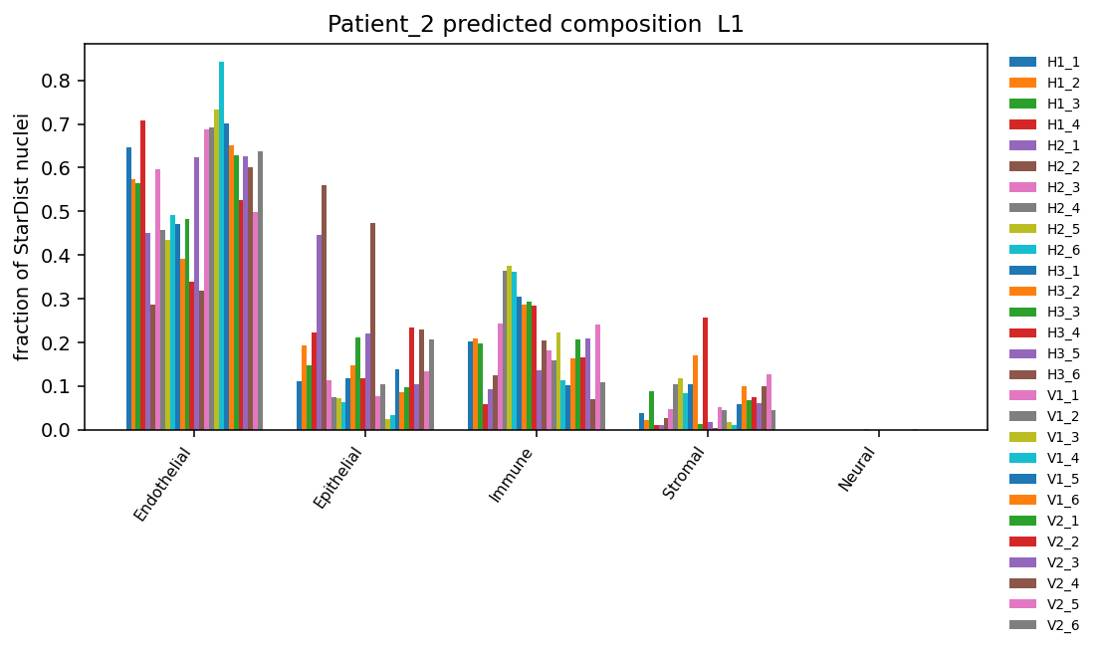

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2_composition_L1.png

===== Patient_2 L12 =====


fraction                                                          \
section         H1_1   H1_2   H1_3   H1_4   H2_1   H2_2   H2_3   H2_4   H2_5   
class                                                                          
Myeloid        0.200  0.092  0.193  0.247  0.408  0.465  0.174  0.159  0.232   
T_cell         0.521  0.690  0.475  0.310  0.279  0.192  0.583  0.607  0.527   
Stromal        0.077  0.044  0.186  0.045  0.022  0.042  0.119  0.169  0.166   
Endothelial    0.115  0.082  0.083  0.211  0.101  0.055  0.088  0.047  0.049   
Epithelial     0.009  0.019  0.022  0.069  0.065  0.083  0.012  0.010  0.010   
Tumor          0.075  0.072  0.041  0.119  0.120  0.160  0.023  0.008  0.016   
B_Plasma       0.003  0.000  0.001  0.000  0.005  0.003  0.000  0.000  0.000   

                    ...         n                                        \
section       H2_6  ...      V1_3      V1_4      V1_5     V1_6     V2_1   
class               ...                                                   
Myeloid      0.306  ...  153909.0  203227.0   53379.0  49919.0  31160.0   
T_cell       0.509  ...   64259.0   29624.0  103224.0  31527.0  72850.0   
Stromal      0.114  ...    8171.0    6379.0   51704.0  23126.0  26012.0   
Endothelial  0.039  ...   11554.0   21280.0   52744.0  12229.0  15539.0   
Epithelial   0.007  ...     135.0      70.0   17949.0    556.0   2650.0   
Tumor        0.024  ...    1521.0    3516.0   10891.0   3729.0   5604.0   
B_Plasma     0.002  ...    2432.0      91.0      65.0    180.0    466.0   

                                                             
section          V2_2      V2_3     V2_4      V2_5     V2_6  
class                                                        
Myeloid       37890.0   51528.0  95838.0   65577.0  47888.0  
T_cell       161567.0  134876.0  86041.0  131348.0  69267.0  
Stromal       34606.0   36895.0  83400.0   74928.0  20918.0  
Endothelial   30424.0   24751.0  49914.0   28801.0  27801.0  
Epithelial    10228.0    4553.0  40386.0    8502.0  11921.0  
Tumor         49584.0    8384.0  13485.0   12854.0  10269.0  
B_Plasma        405.0     137.0     69.0     105.0    282.0  

[7 rows x 84 columns]

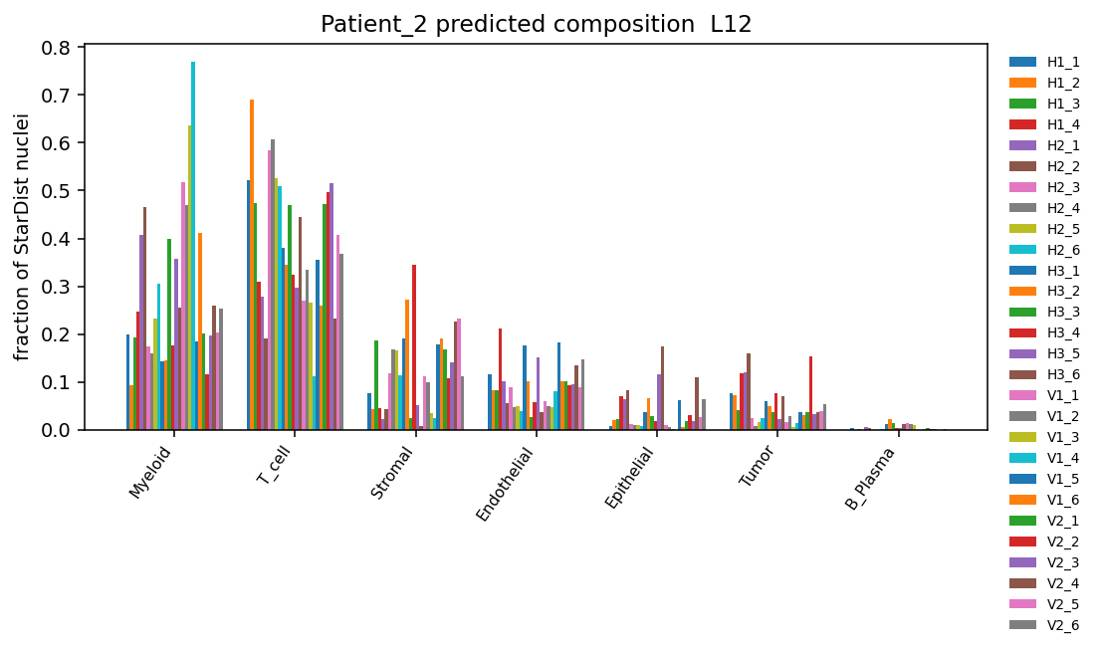

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2_composition_L12.png

===== Patient_2 L2 =====


fraction                                                   \
section               H1_1   H1_2   H1_3   H1_4   H2_1   H2_2   H2_3   H2_4   
class                                                                         
Endothelial          0.375  0.313  0.357  0.545  0.335  0.217  0.408  0.239   
Neutrophil           0.045  0.012  0.022  0.039  0.075  0.112  0.023  0.017   
CD4_T                0.078  0.233  0.088  0.017  0.101  0.055  0.225  0.262   
Fibroblast           0.072  0.050  0.062  0.035  0.032  0.073  0.064  0.169   
Epithelial           0.012  0.025  0.032  0.093  0.149  0.181  0.023  0.015   
CD8_T                0.229  0.241  0.227  0.095  0.035  0.024  0.136  0.192   
B_cell               0.068  0.026  0.040  0.016  0.052  0.055  0.036  0.034   
Tumor                0.086  0.079  0.047  0.115  0.154  0.190  0.036  0.013   
Macrophage           0.018  0.006  0.038  0.014  0.042  0.048  0.020  0.039   
Stromal              0.011  0.009  0.078  0.007  0.005  0.001  0.016  0.003   
DCIS                 0.001  0.001  0.002  0.001  0.000  0.003  0.000  0.000   
DC                   0.001  0.002  0.000  0.018  0.015  0.038  0.002  0.001   
Plasma               0.001  0.001  0.003  0.000  0.000  0.000  0.009  0.016   
Myofibroblast        0.000  0.000  0.004  0.000  0.000  0.001  0.001  0.001   
Injury_epithelial    0.000  0.000  0.001  0.000  0.001  0.001  0.000  0.000   
Tregs                0.000  0.001  0.000  0.001  0.001  0.002  0.000  0.000   
Myoepithelial        0.000  0.000  0.000  0.003    NaN  0.000    NaN    NaN   
Alveolar               NaN    NaN    NaN    NaN  0.000  0.000  0.000  0.000   
NK                   0.000  0.000  0.000    NaN  0.000    NaN  0.000  0.000   
Neural                 NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   

                                 ...        n                               \
section             H2_5   H2_6  ...     V1_3      V1_4      V1_5     V1_6   
class                            ...                                         
Endothelial        0.242  0.245  ...  92809.0  112212.0  167655.0  56224.0   
Neutrophil         0.021  0.020  ...  71439.0  114176.0    2703.0   4469.0   
CD4_T              0.253  0.136  ...  17482.0    9025.0   32634.0   6442.0   
Fibroblast         0.158  0.150  ...  14065.0   11508.0   10956.0   9182.0   
Epithelial         0.014  0.013  ...    121.0     272.0   14882.0   1100.0   
CD8_T              0.135  0.186  ...   4053.0    1721.0   20711.0   8736.0   
B_cell             0.047  0.128  ...  36126.0    3516.0    5942.0   5313.0   
Tumor              0.028  0.035  ...   3241.0    6515.0   11250.0   5709.0   
Macrophage         0.081  0.069  ...   1553.0    3085.0    7593.0  14635.0   
Stromal            0.002  0.001  ...     21.0     152.0   11179.0   6624.0   
DCIS                 NaN  0.001  ...      NaN       NaN     223.0      NaN   
DC                 0.003  0.008  ...    206.0      16.0     532.0     75.0   
Plasma             0.012  0.007  ...    849.0    1968.0    1130.0   1251.0   
Myofibroblast      0.005  0.001  ...     13.0      18.0     995.0   1295.0   
Injury_epithelial  0.001  0.000  ...      NaN       1.0     762.0     70.0   
Tregs              0.000  0.000  ...      NaN       1.0     240.0     71.0   
Myoepithelial        NaN  0.000  ...      NaN       NaN     464.0      1.0   
Alveolar           0.000  0.000  ...      1.0       NaN       2.0      2.0   
NK                 0.001  0.000  ...      2.0       1.0     103.0     64.0   
Neural               NaN    NaN  ...      NaN       NaN       NaN      3.0   

                                                                             
section               V2_1      V2_2      V2_3      V2_4      V2_5     V2_6  
class                                                                        
Endothelial        67034.0  101631.0  109611.0  189453.0  109896.0  88519.0  
Neutrophil          1749.0     679.0    3422.0    7421.0    3530.0   5751.0  
CD4_T          

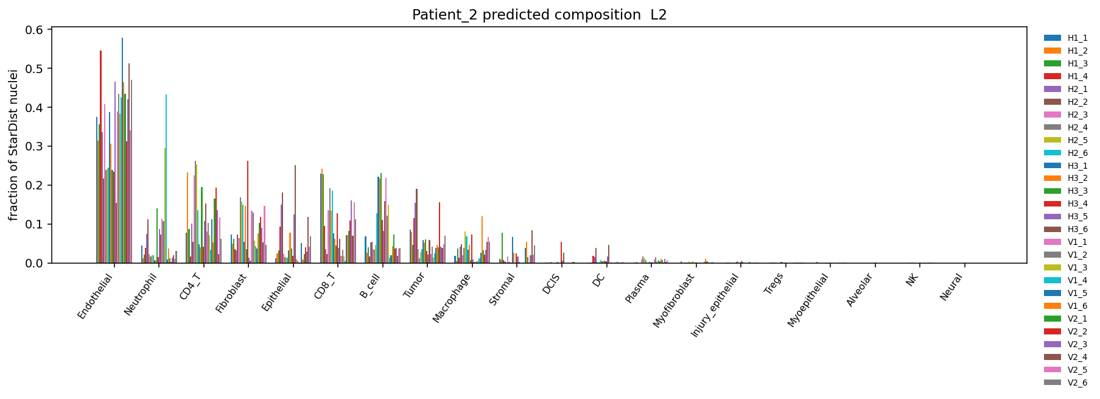

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2_composition_L2.png
Patient_2__H1_1


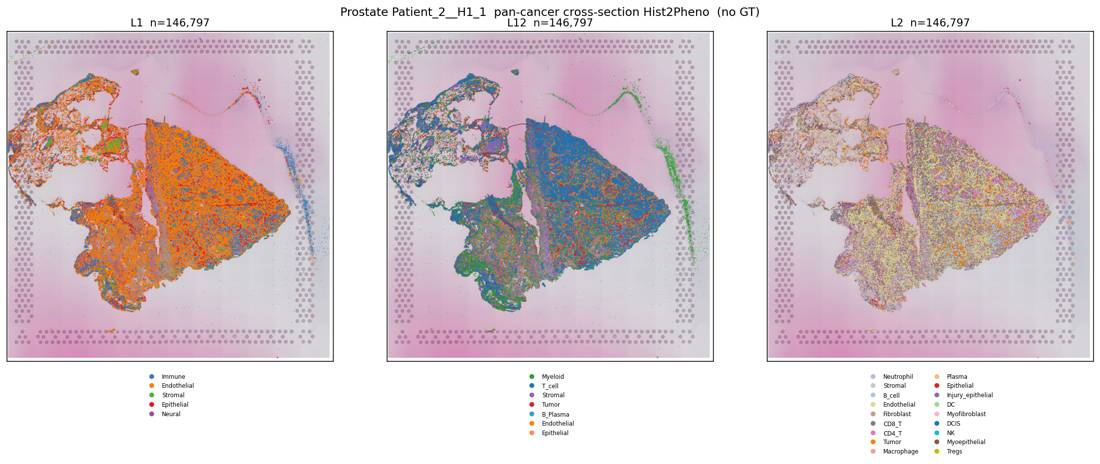

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_1_spatial_L1_L12_L2.png
Patient_2__H1_2


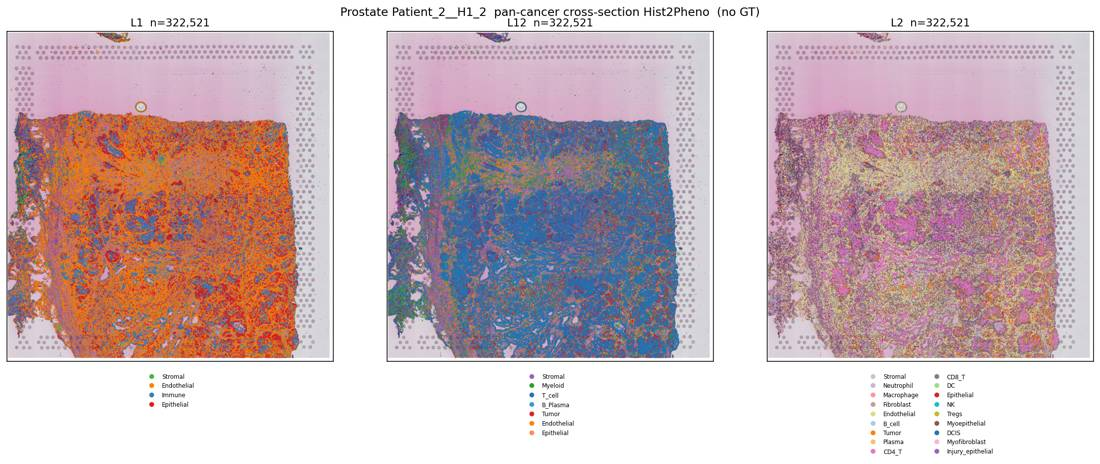

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_2_spatial_L1_L12_L2.png
Patient_2__H1_3


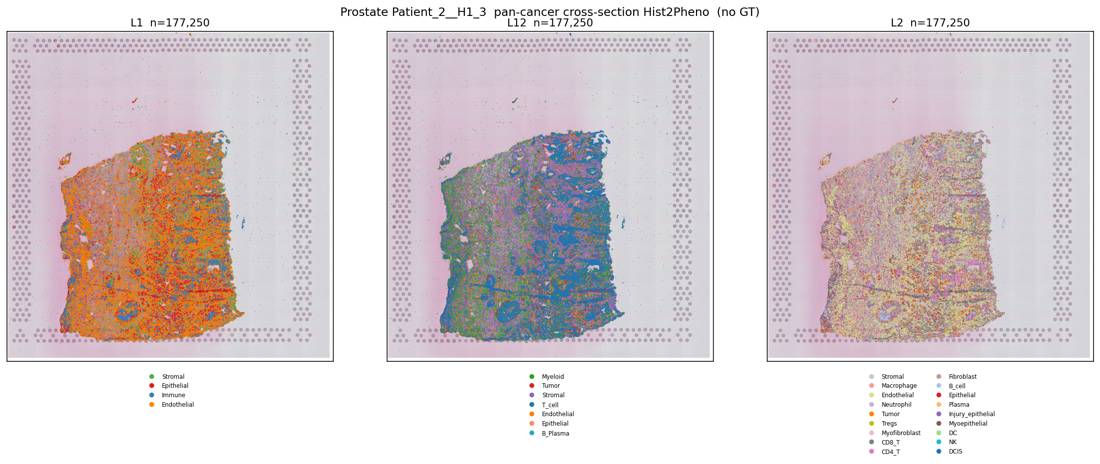

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_3_spatial_L1_L12_L2.png
Patient_2__H1_4


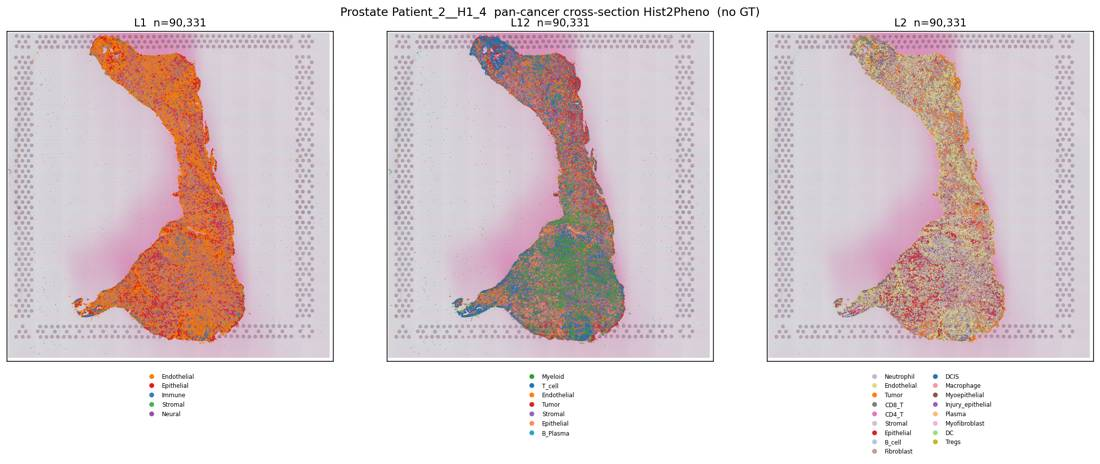

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_4_spatial_L1_L12_L2.png
Patient_2__H2_1


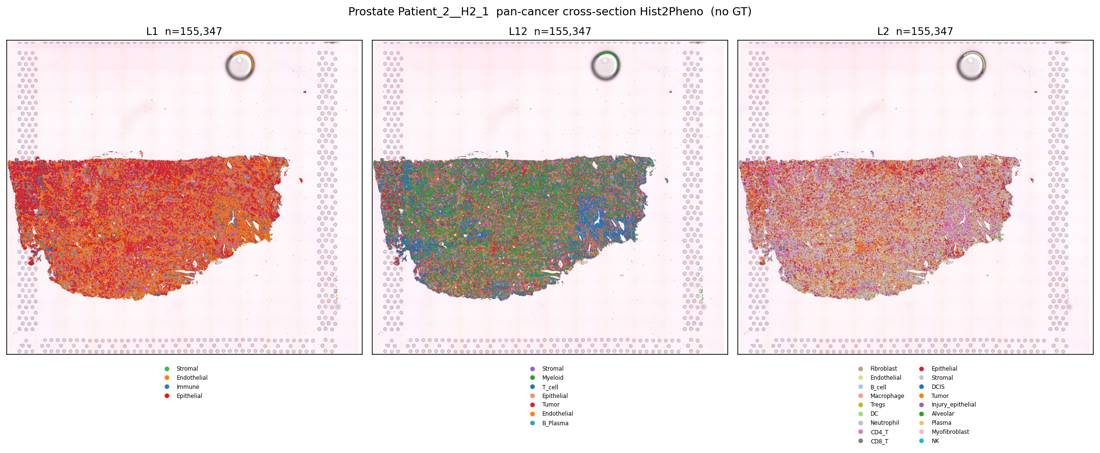

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_1_spatial_L1_L12_L2.png
Patient_2__H2_2


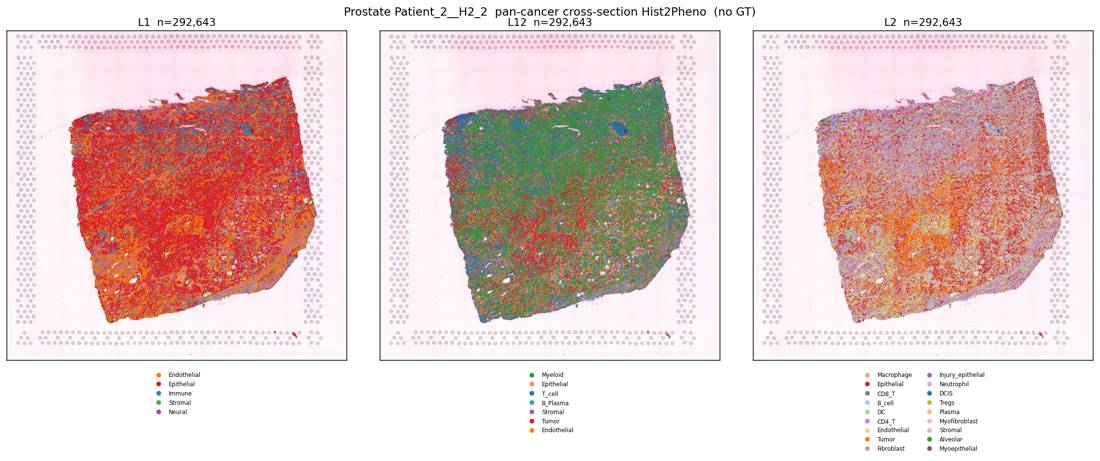

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_2_spatial_L1_L12_L2.png
Patient_2__H2_3


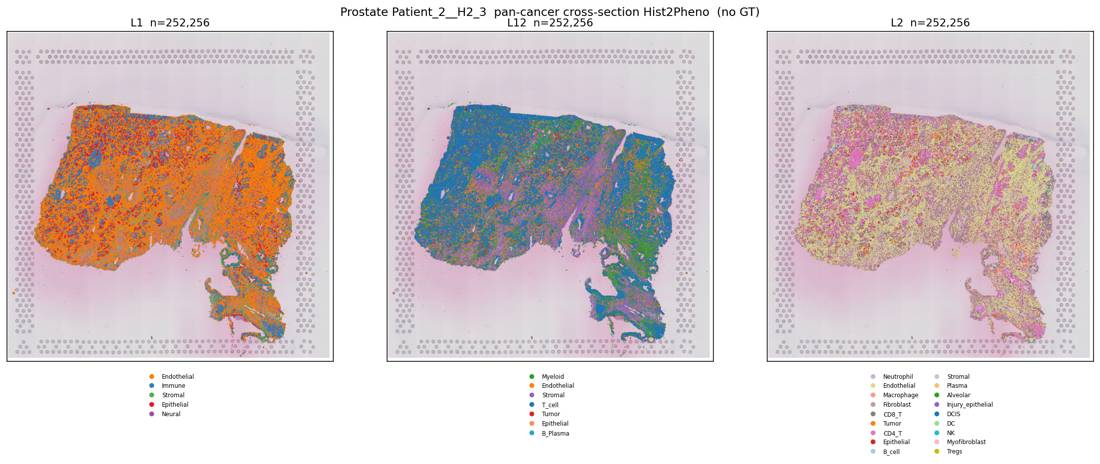

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_3_spatial_L1_L12_L2.png
Patient_2__H2_4


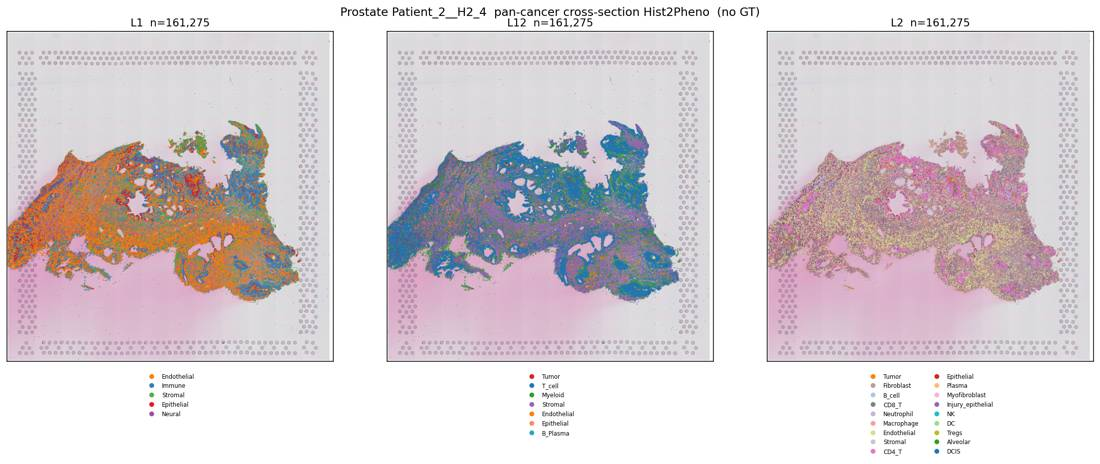

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_4_spatial_L1_L12_L2.png
Patient_2__H2_5


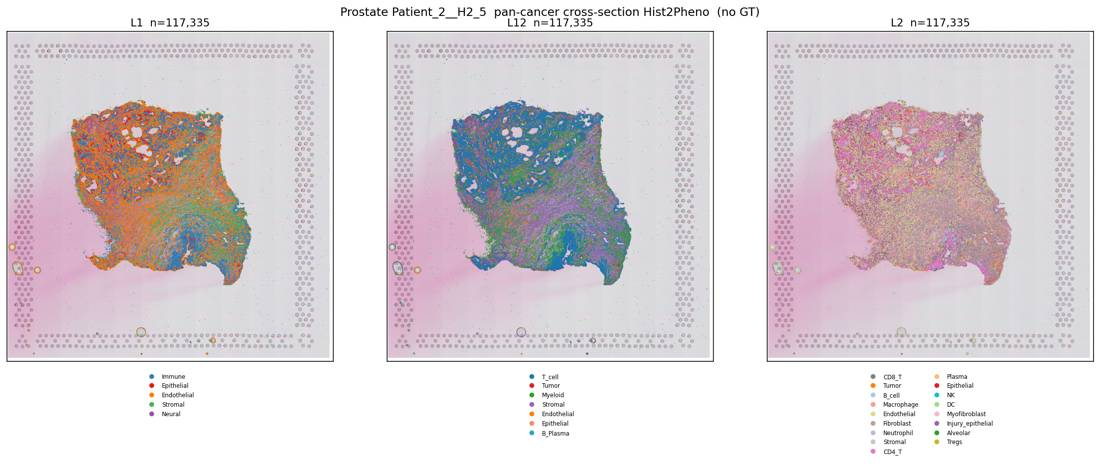

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_5_spatial_L1_L12_L2.png
Patient_2__H2_6


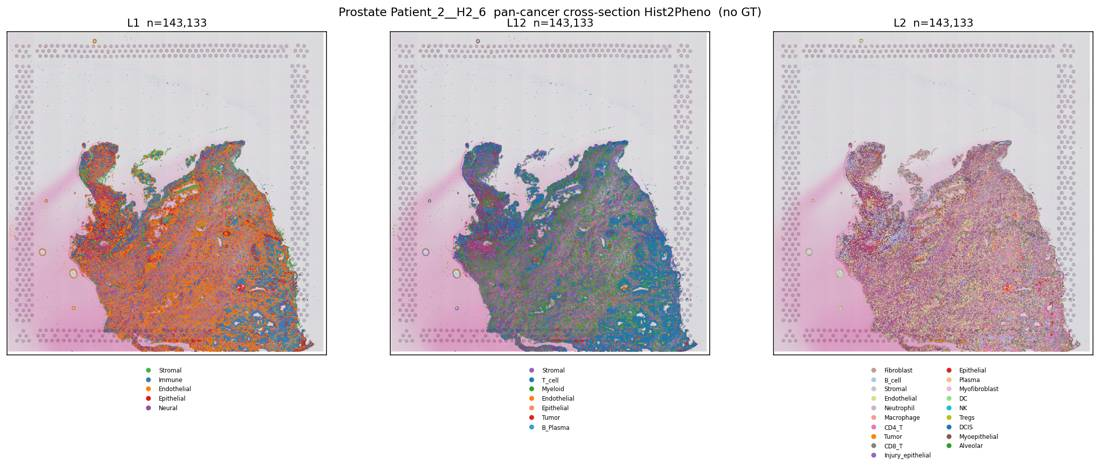

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_6_spatial_L1_L12_L2.png
Patient_2__H3_1


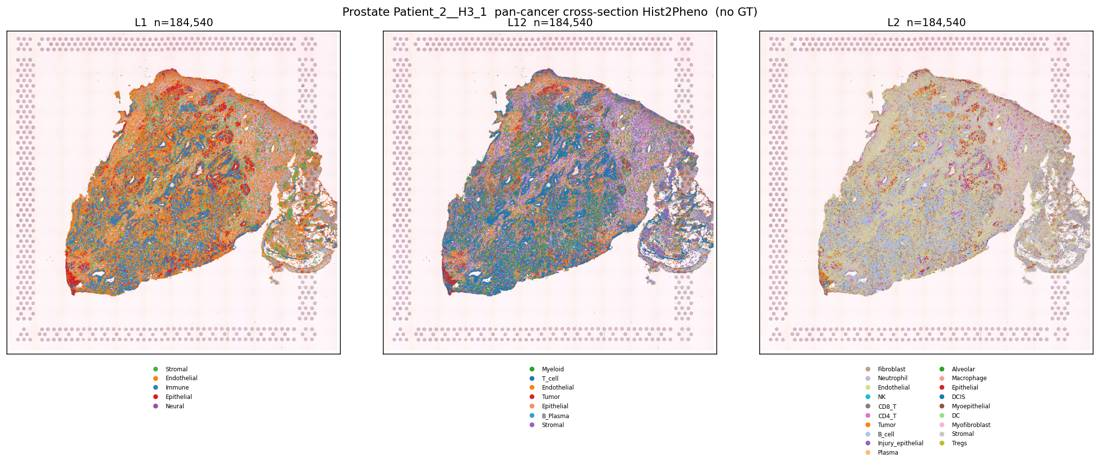

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_1_spatial_L1_L12_L2.png
Patient_2__H3_2


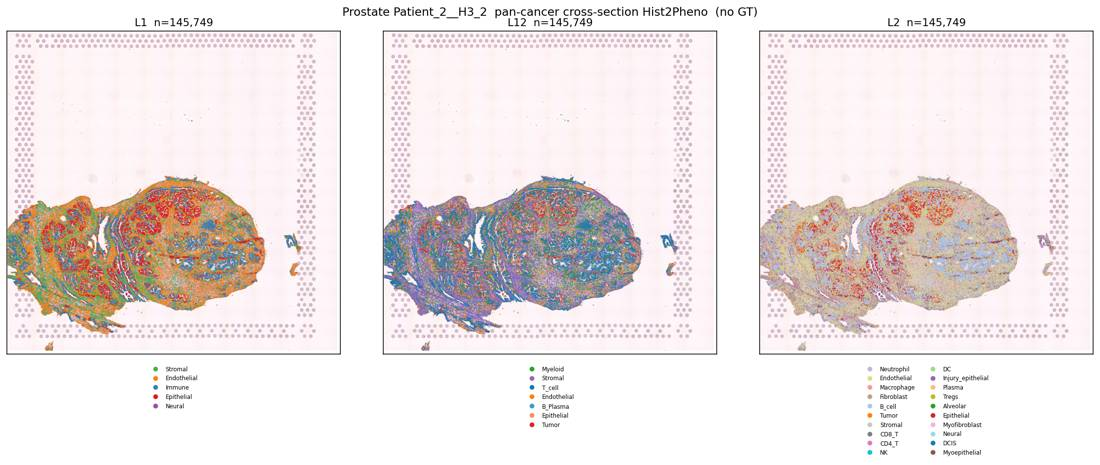

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_2_spatial_L1_L12_L2.png
Patient_2__H3_3


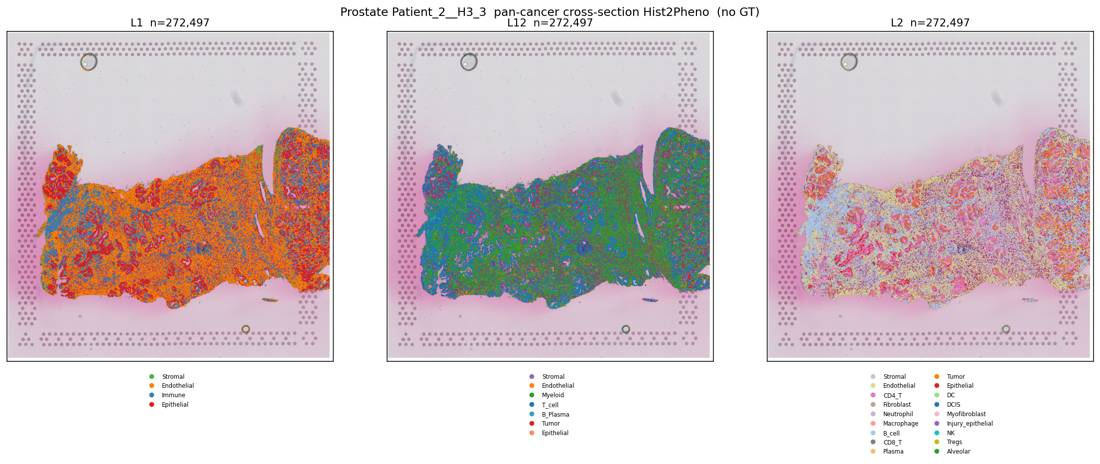

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_3_spatial_L1_L12_L2.png
Patient_2__H3_4


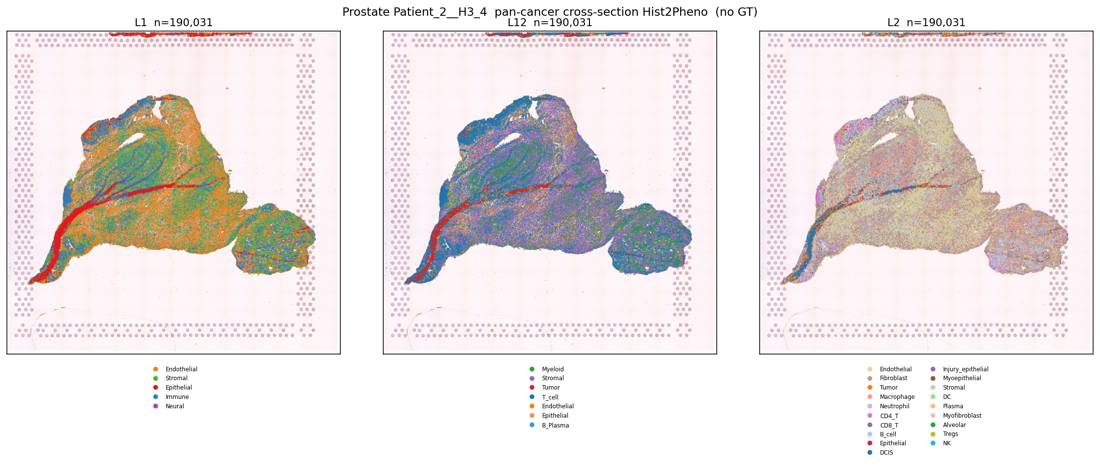

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_4_spatial_L1_L12_L2.png
Patient_2__H3_5


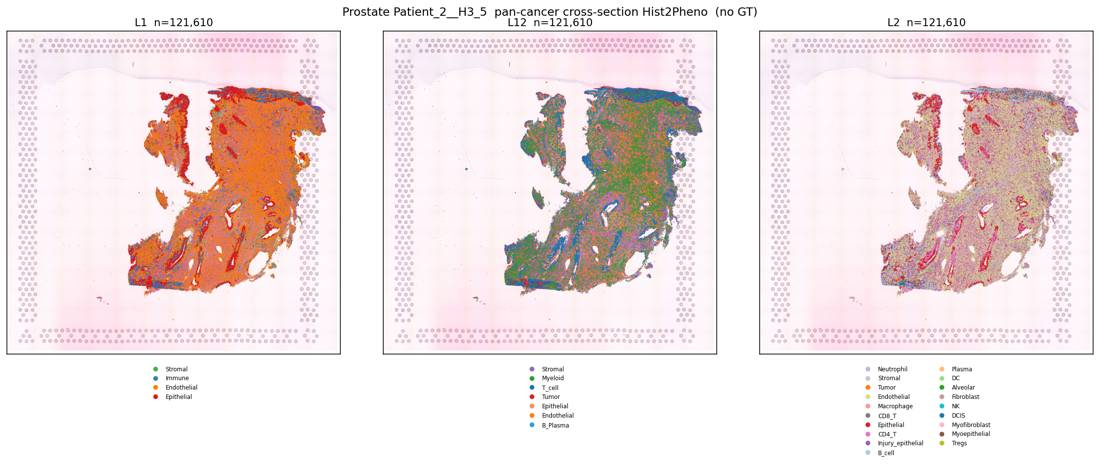

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_5_spatial_L1_L12_L2.png
Patient_2__H3_6


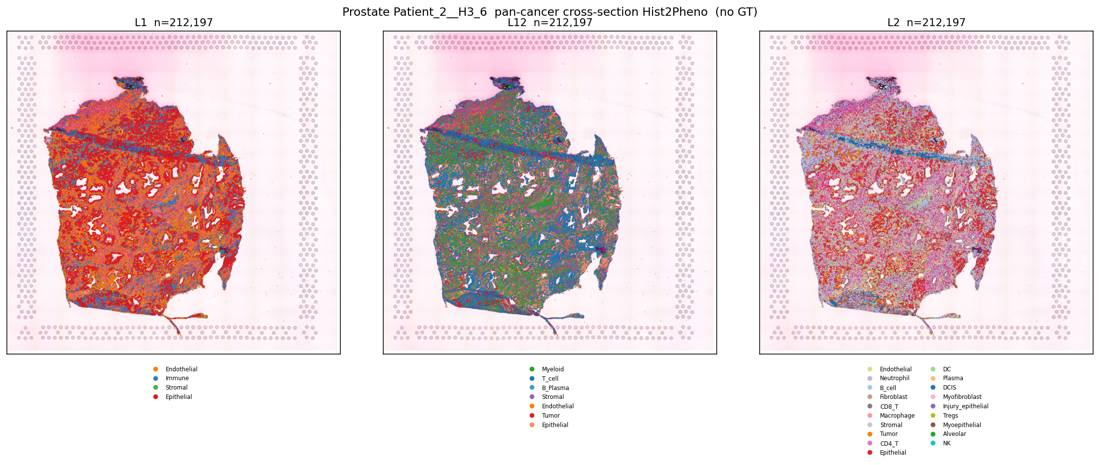

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_6_spatial_L1_L12_L2.png
Patient_2__V1_1


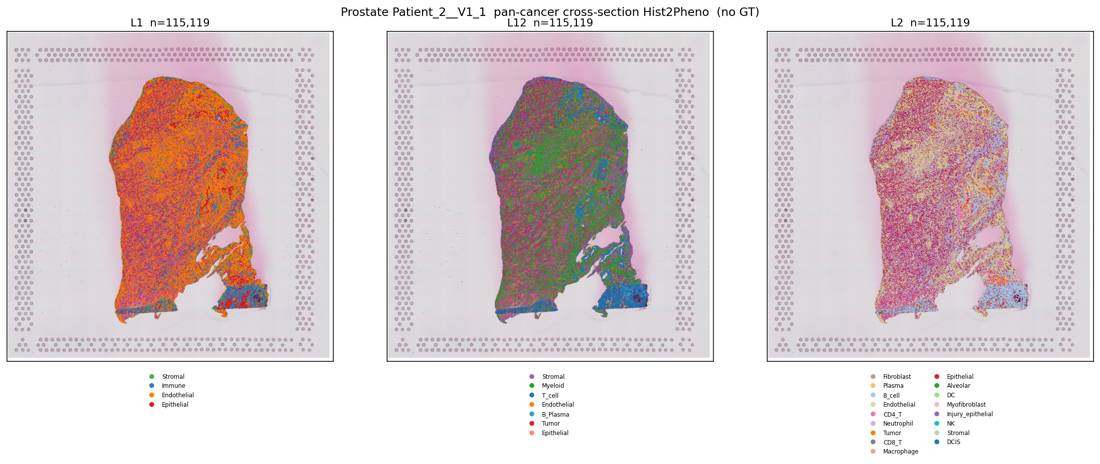

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_1_spatial_L1_L12_L2.png
Patient_2__V1_2


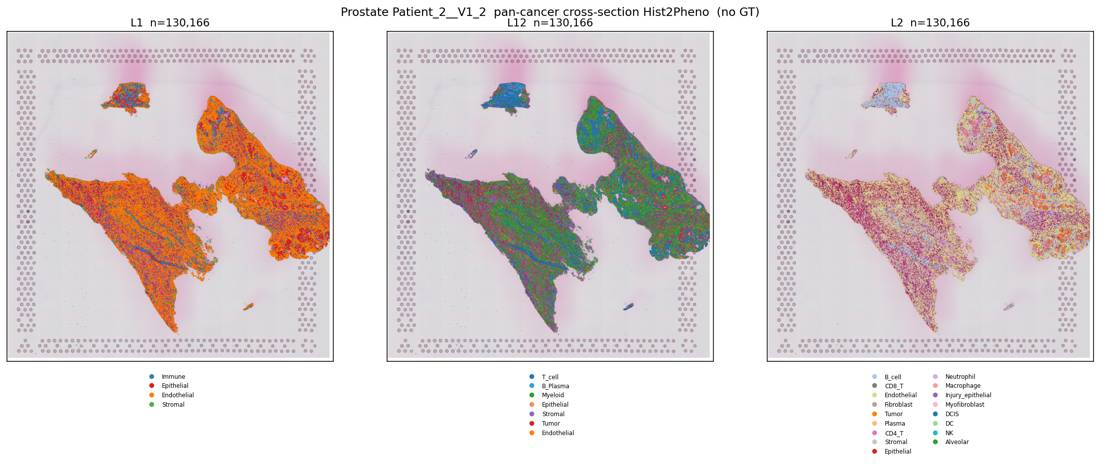

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_2_spatial_L1_L12_L2.png
Patient_2__V1_3


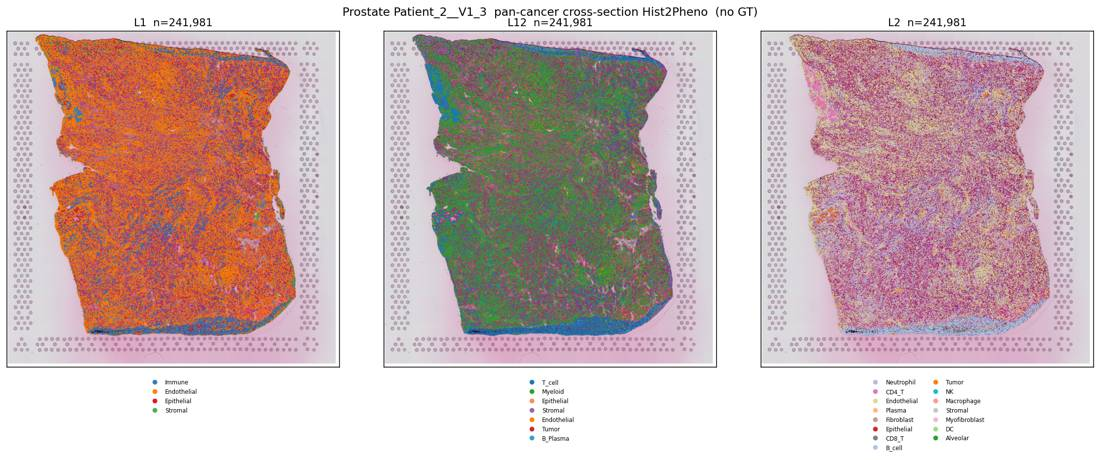

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_3_spatial_L1_L12_L2.png
Patient_2__V1_4


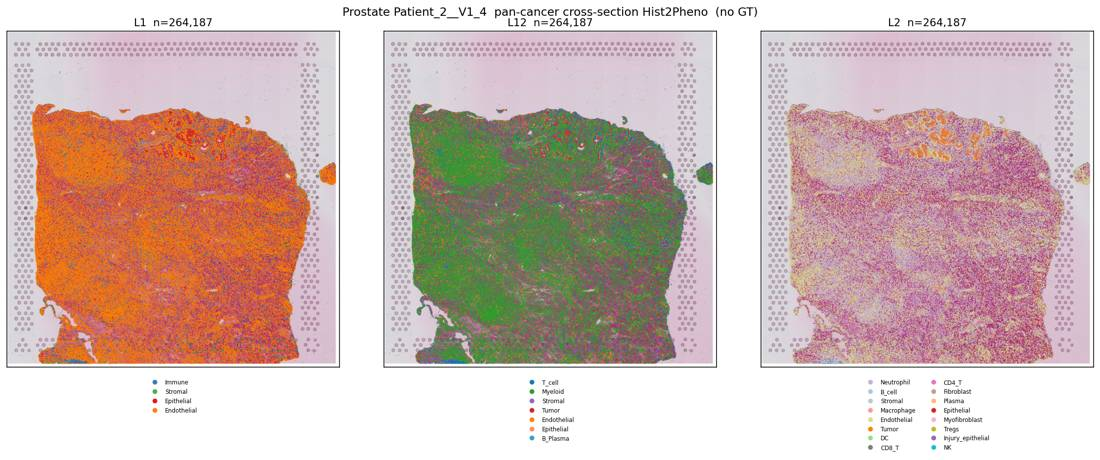

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_4_spatial_L1_L12_L2.png
Patient_2__V1_5


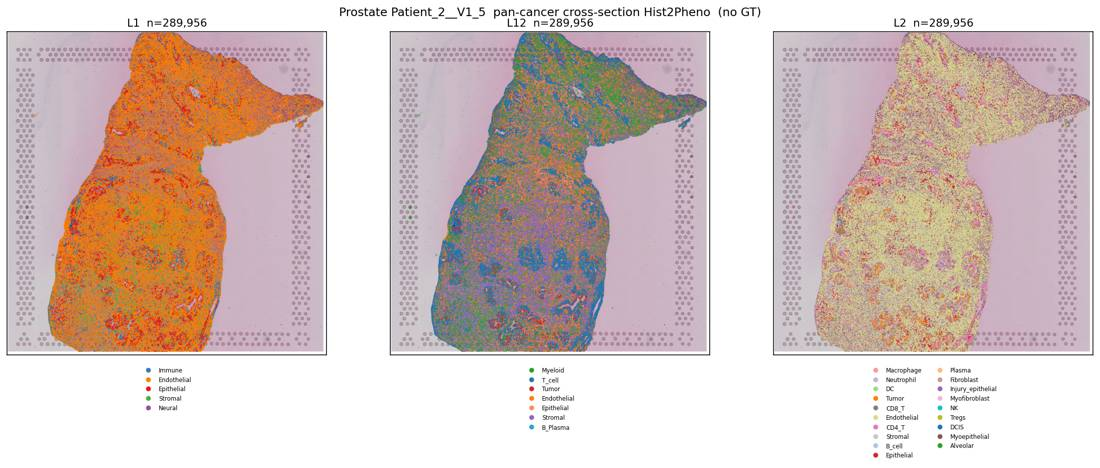

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_5_spatial_L1_L12_L2.png
Patient_2__V1_6


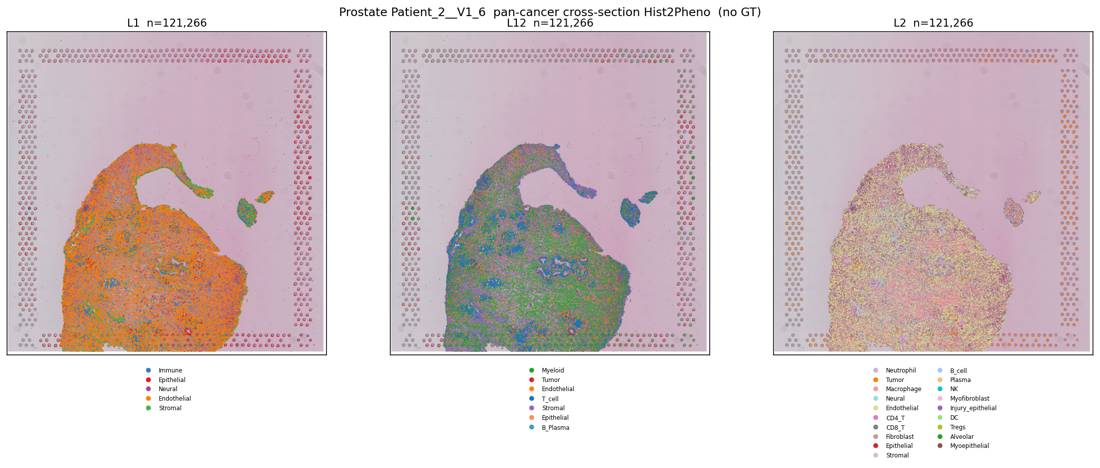

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_6_spatial_L1_L12_L2.png
Patient_2__V2_1


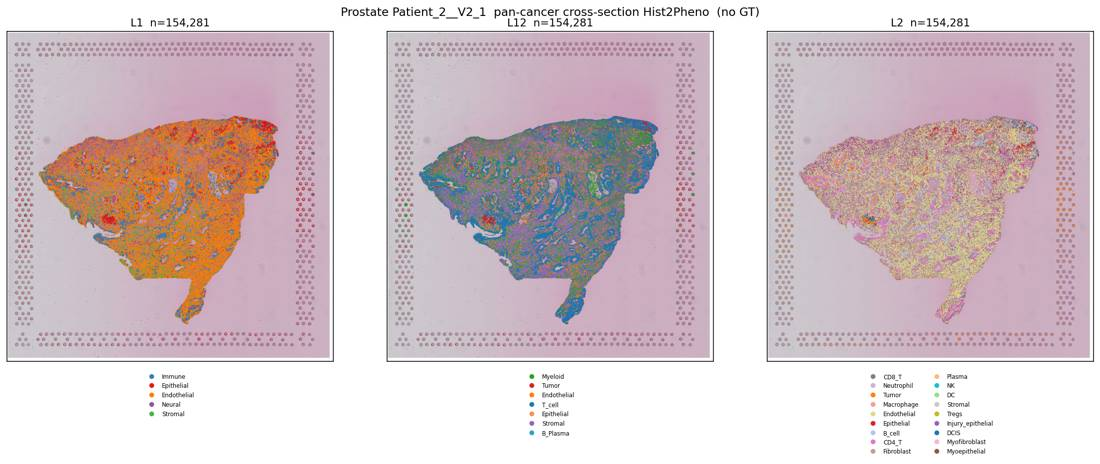

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_1_spatial_L1_L12_L2.png
Patient_2__V2_2


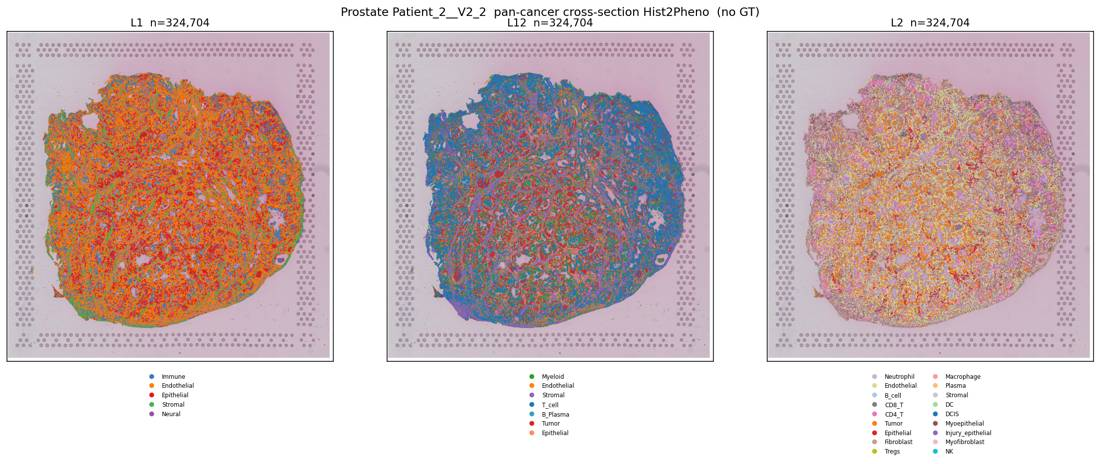

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_2_spatial_L1_L12_L2.png
Patient_2__V2_3


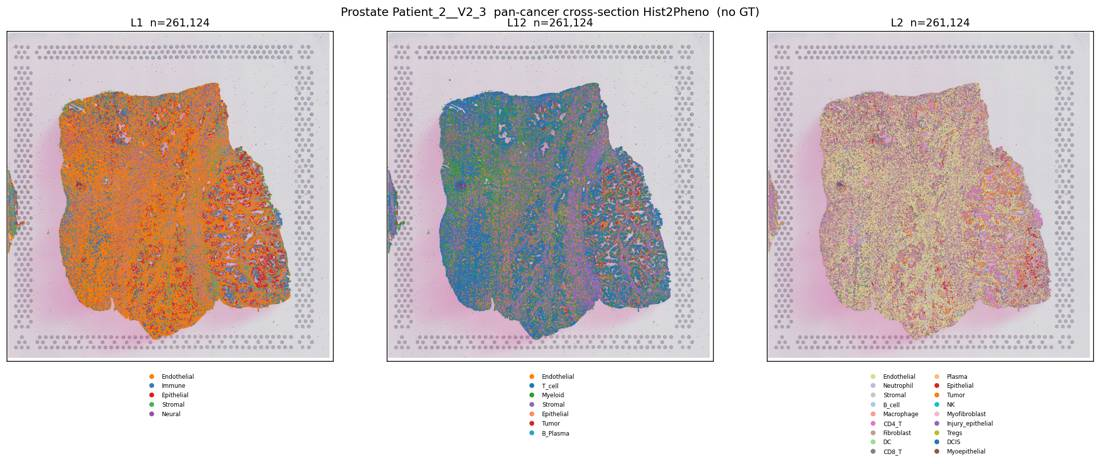

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_3_spatial_L1_L12_L2.png
Patient_2__V2_4


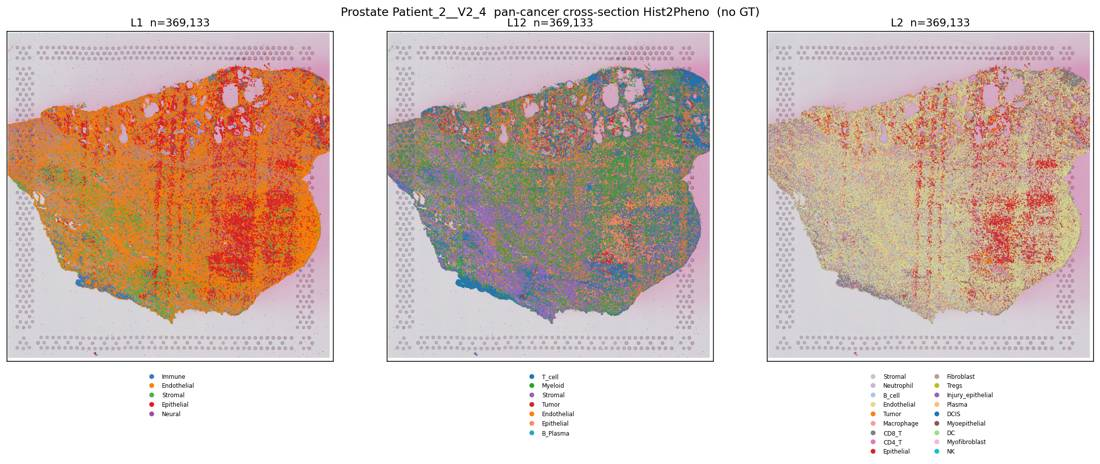

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_4_spatial_L1_L12_L2.png
Patient_2__V2_5


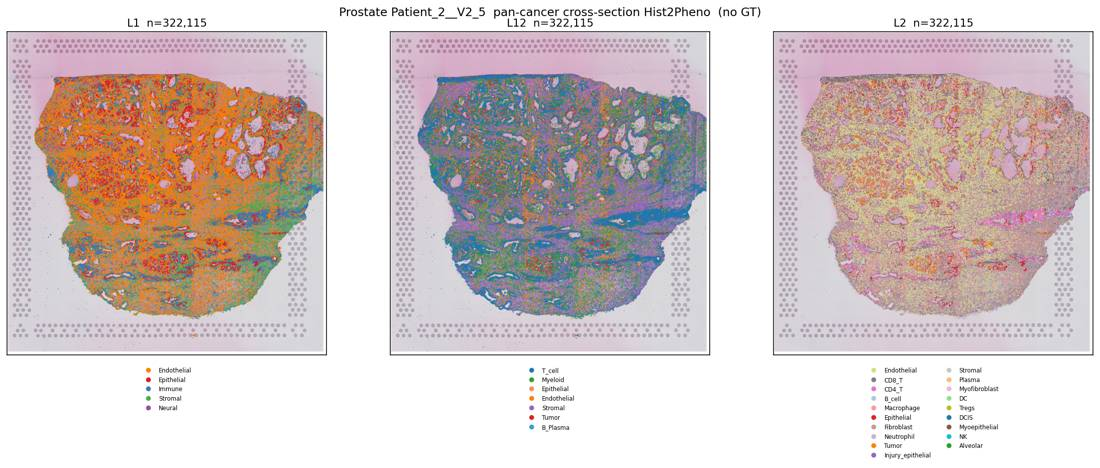

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_5_spatial_L1_L12_L2.png
Patient_2__V2_6


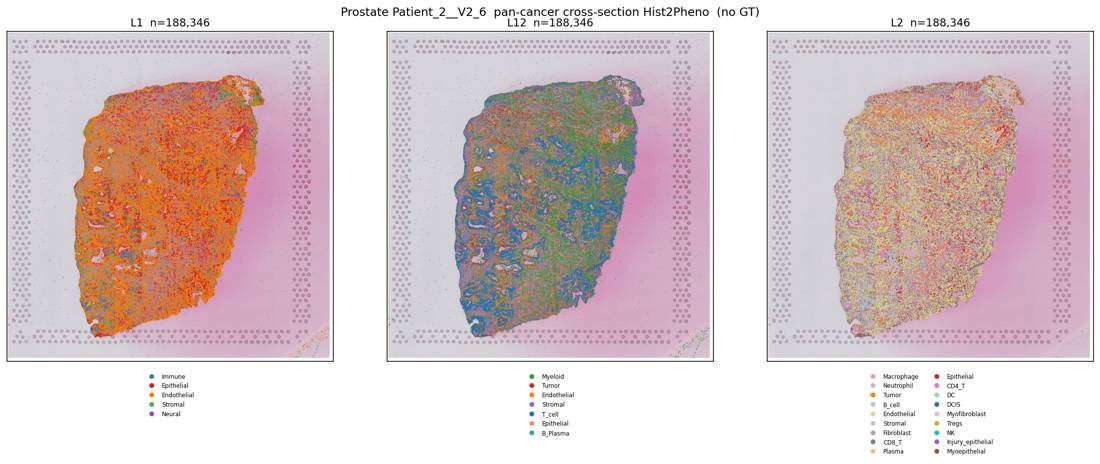

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_6_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/Prostate/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    sub["section"] = sub["sample"].str.split("__").str[-1]
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="section", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["section"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["section"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    out = fig_dir / f"{PATIENT}_composition_{head}.png"
    fig.savefig(out, dpi=140, bbox_inches="tight")
    plt.close(fig)
    show_preview(out)

spatial_missing = [
    s for s in group if not (fig_dir / f"{s}_spatial_L1_L12_L2.png").is_file()
]
if spatial_missing:
    cmd_plot(group)
    for head in ("L1", "L12", "L2"):
        src = fig_dir / f"composition_{head}.png"
        if src.is_file():
            shutil.copy(src, fig_dir / f"{PATIENT}_composition_{head}.png")
for sample in group:
    print(sample)
    show_preview(fig_dir / f"{sample}_spatial_L1_L12_L2.png")


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with **that slide's** µm/px, not 0.5. TLS, SRI, and TNI each use a 1×3 row. Previews in this notebook are resized; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

PROSTATE_NICHE = OrganNicheConfig(
    pan_organ="pancancer_prostate",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="Prostate",
)
display(hni.index_formula_table(PROSTATE_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## Patient_2 — TLS / SRI / TNI

[niche] cache Patient_2__H1_1_niche_indices.h5ad  n=146,797  µm/px=0.3414
  TLS hotspot: {'n_cells_total': 146797, 'n_candidate_cells': 7340, 'fraction_candidate': 0.05000102181924699, 'max_tls_spatial': 0.1760718951450553, 'mean_tls_spatial_candidate': 0.1409879416824828, 'centroid_x': 13701.147021934024, 'centroid_y': 12237.245404785011}
  mean TLS=0.410  TLS_spatial=0.097  SRI=2.362  TNI=6.893
[niche] cache Patient_2__H1_2_niche_indices.h5ad  n=322,521  µm/px=0.3414
  TLS hotspot: {'n_cells_total': 322521, 'n_candidate_cells': 16127, 'fraction_candidate': 0.0500029455446312, 'max_tls_spatial': 0.20124169919113274, 'mean_tls_spatial_candidate': 0.13977095406465806, 'centroid_x': 11779.151599690069, 'centroid_y': 13974.639826309143}
  mean TLS=0.468  TLS_spatial=0.104  SRI=1.874  TNI=6.099
[niche] cache Patient_2__H1_3_niche_indices.h5ad  n=177,250  µm/px=0.3414
  TLS hotspot: {'n_cells_total': 177250, 'n_candidate_cells': 8863, 'fraction_candidate': 0.05000282087447109, 'max_tls_spat

,sample,section,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,Patient_2__H1_1,H1_1,146797,0.410,0.397,0.700,0.972,0.097,0.097,0.129,0.176,0.595,0.583,0.173,0.294,0.120,0.608
1,Patient_2__H1_2,H1_2,322521,0.468,0.459,0.754,0.963,0.104,0.103,0.131,0.201,0.510,0.497,0.140,0.246,0.122,0.631
2,Patient_2__H1_3,H1_3,177250,0.395,0.363,0.745,0.972,0.095,0.092,0.138,0.186,0.673,0.654,0.248,0.397,0.133,0.680
3,Patient_2__H1_4,H1_4,90331,0.312,0.298,0.547,0.927,0.082,0.078,0.124,0.181,0.534,0.533,0.137,0.242,0.104,0.474
4,Patient_2__H2_1,H2_1,155347,0.337,0.322,0.590,0.983,0.091,0.090,0.121,0.171,0.478,0.467,0.123,0.219,0.109,0.492
5,Patient_2__H2_2,H2_2,292643,0.312,0.291,0.589,0.967,0.088,0.084,0.141,0.206,0.621,0.594,0.233,0.378,0.133,0.535
6,Patient_2__H2_3,H2_3,252256,0.445,0.422,0.748,0.964,0.108,0.107,0.146,0.196,0.609,0.625,0.143,0.250,0.135,0.640
7,Patient_2__H2_4,H2_4,161275,0.495,0.480,0.802,0.976,0.119,0.118,0.162,0.208,0.655,0.656,0.165,0.283,0.152,0.708
8,Patient_2__H2_5,H2_5,117335,0.463,0.443,0.808,0.981,0.116,0.116,0.166,0.216,0.687,0.689,0.194,0.326,0.158,0.719
9,Patient_2__H2_6,H2_6,143133,0.473,0.454,0.788,0.977,0.124,0.117,0.181,0.240,0.664,0.642,0.240,0.387,0.175,0.719


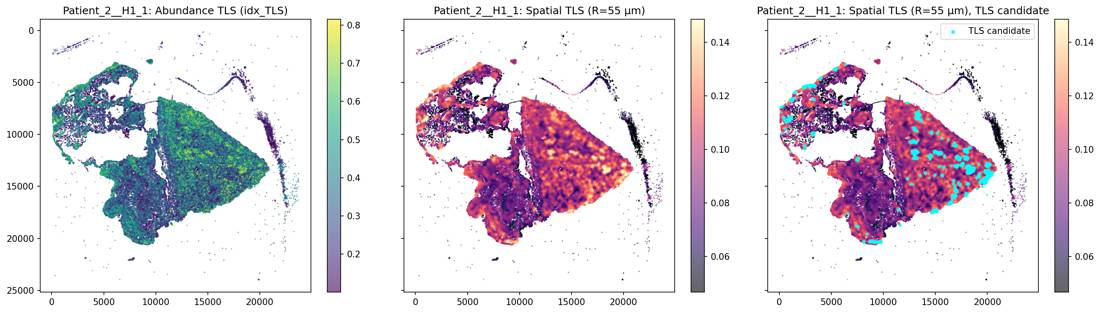

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_1_TLS_abundance_vs_spatial.png


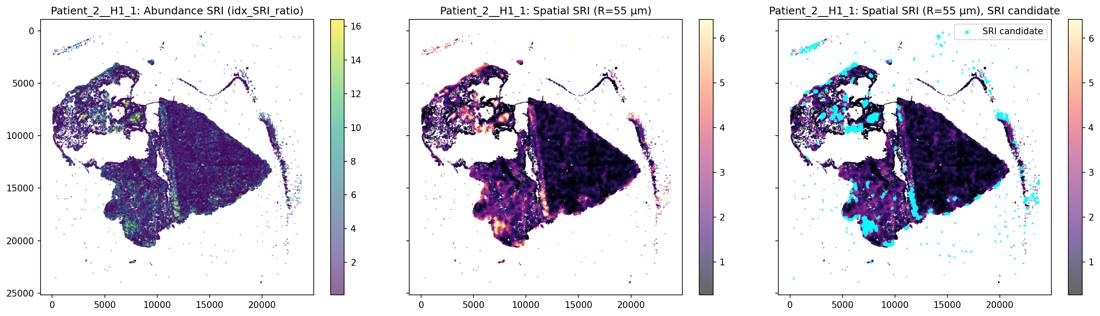

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_1_SRI_abundance_vs_spatial.png


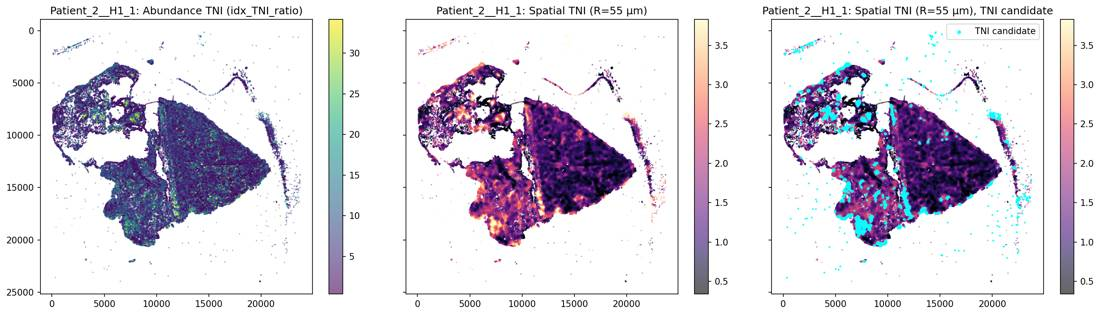

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_1_TNI_abundance_vs_spatial.png


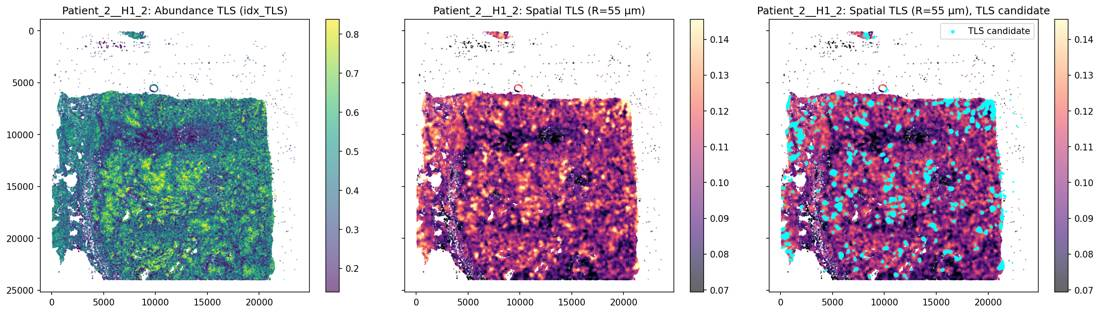

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_2_TLS_abundance_vs_spatial.png


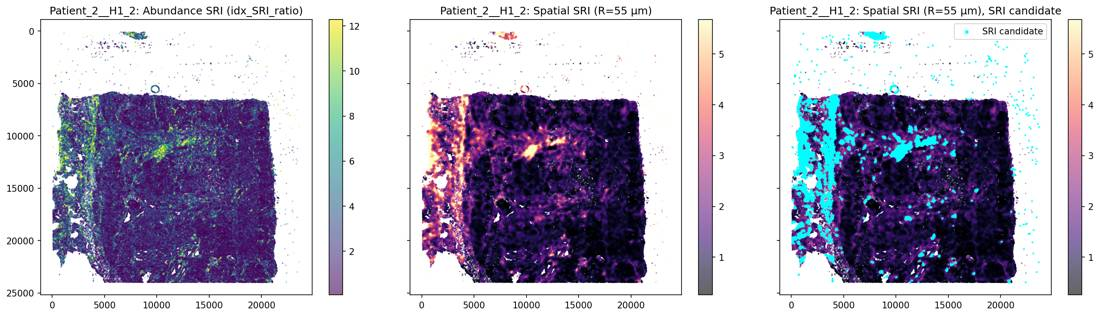

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_2_SRI_abundance_vs_spatial.png


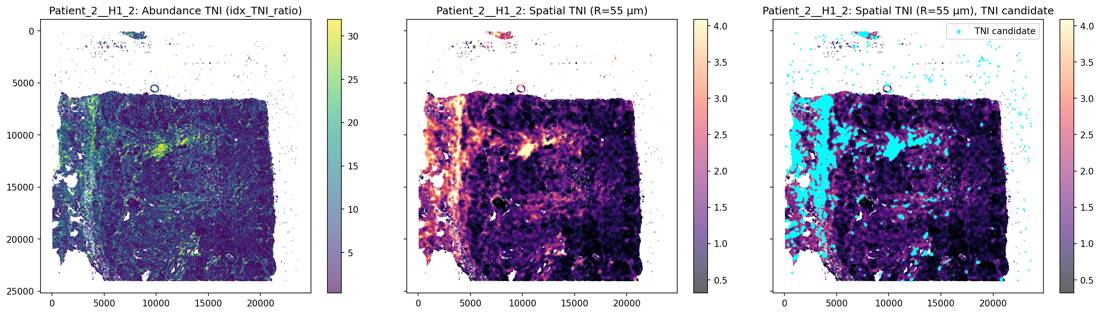

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_2_TNI_abundance_vs_spatial.png


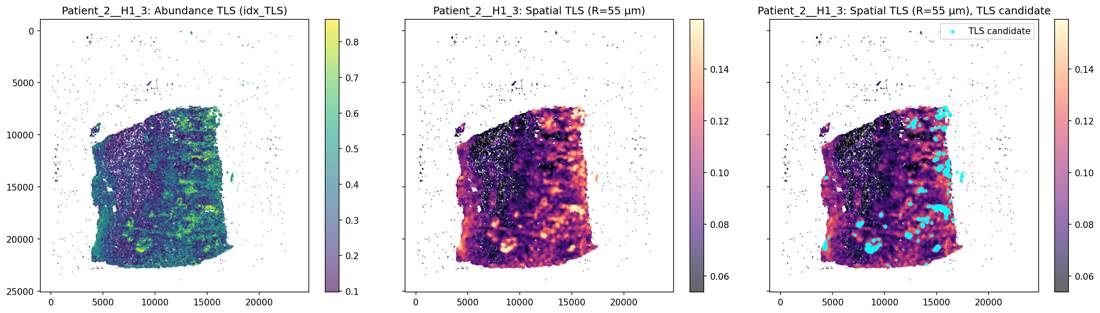

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_3_TLS_abundance_vs_spatial.png


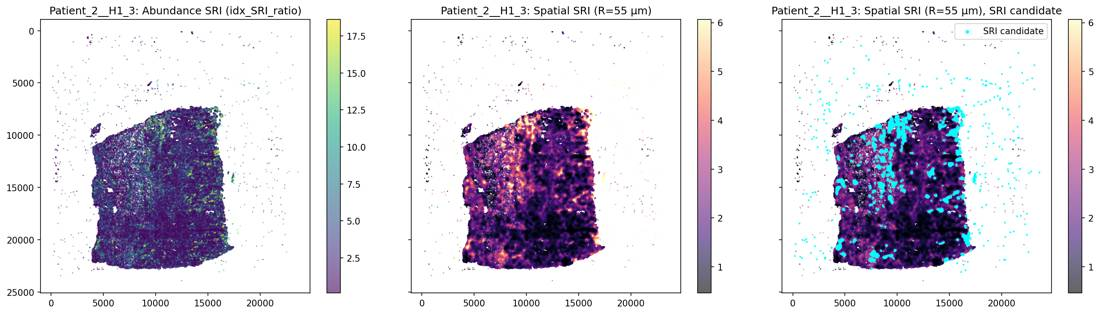

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_3_SRI_abundance_vs_spatial.png


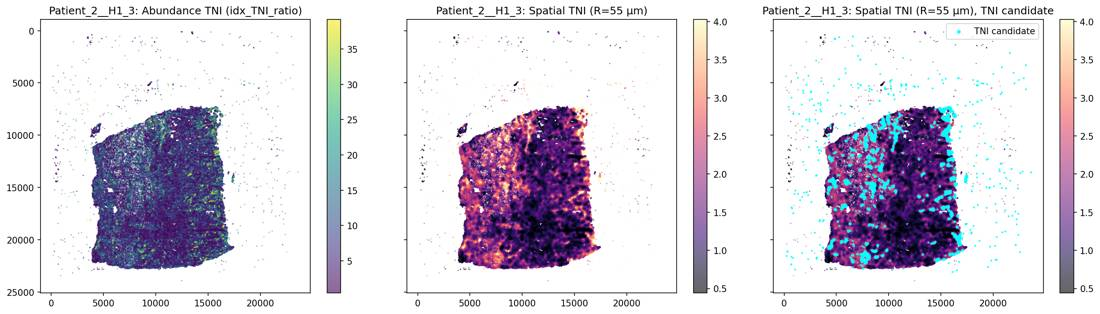

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_3_TNI_abundance_vs_spatial.png


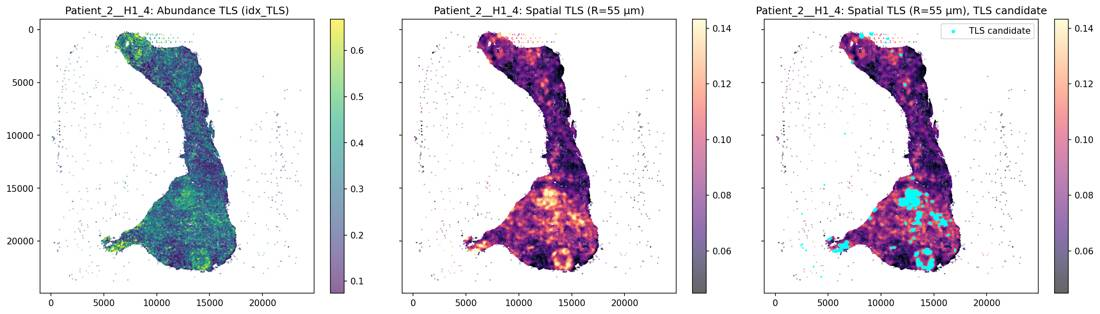

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_4_TLS_abundance_vs_spatial.png


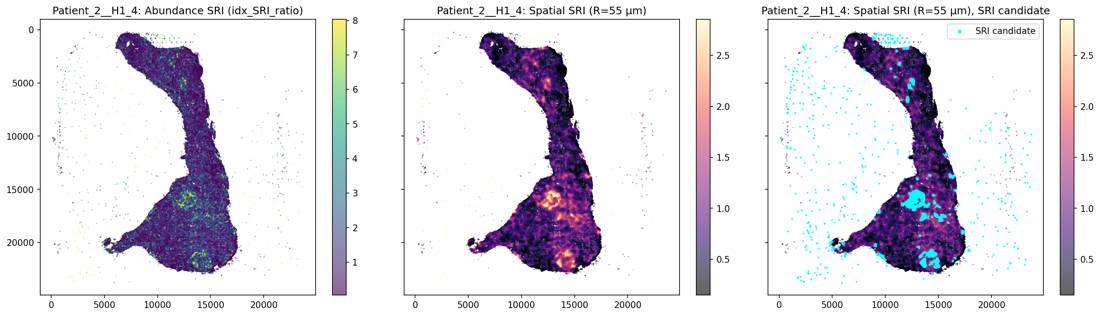

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_4_SRI_abundance_vs_spatial.png


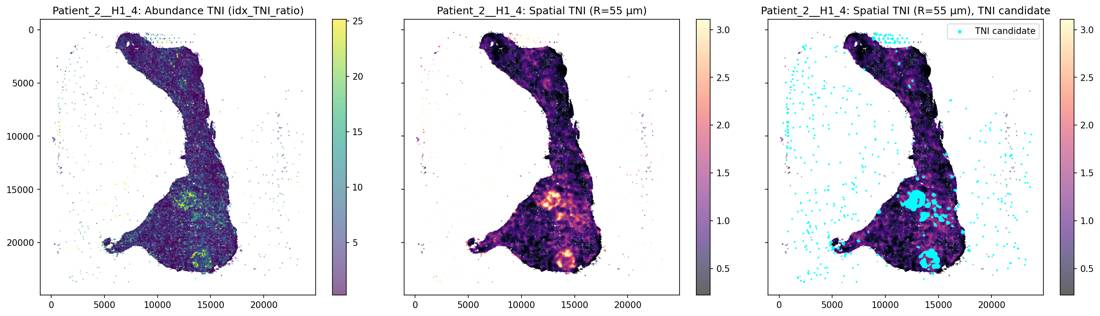

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H1_4_TNI_abundance_vs_spatial.png


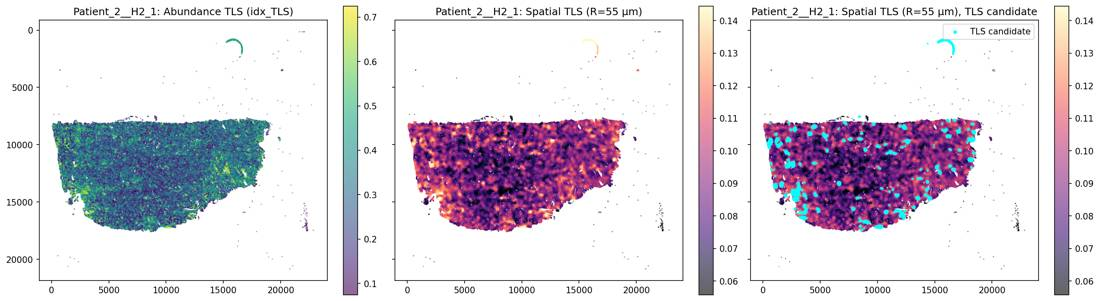

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_1_TLS_abundance_vs_spatial.png


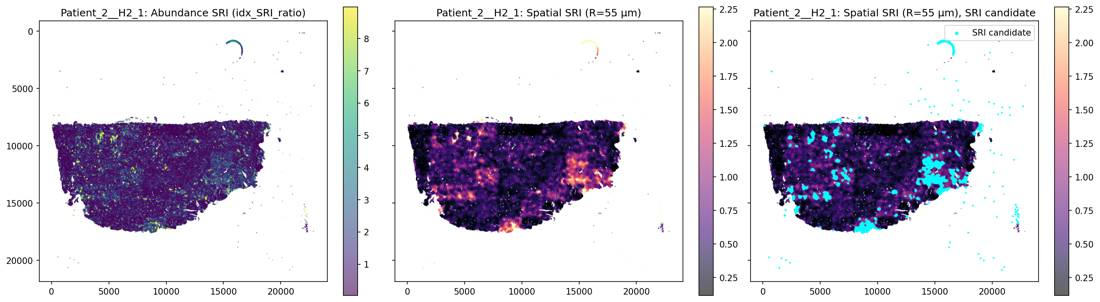

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_1_SRI_abundance_vs_spatial.png


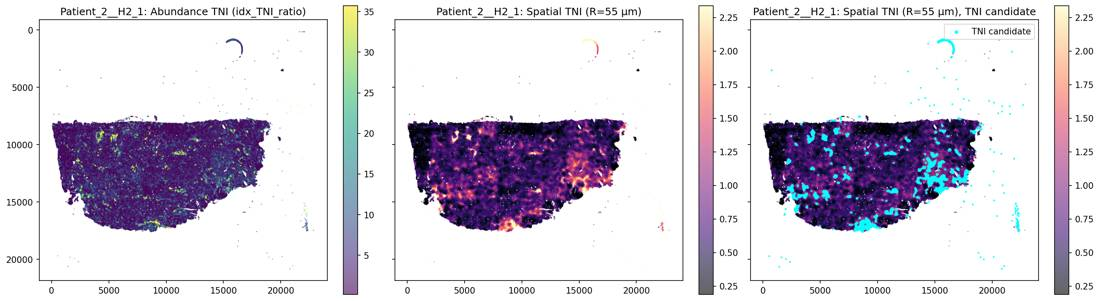

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_1_TNI_abundance_vs_spatial.png


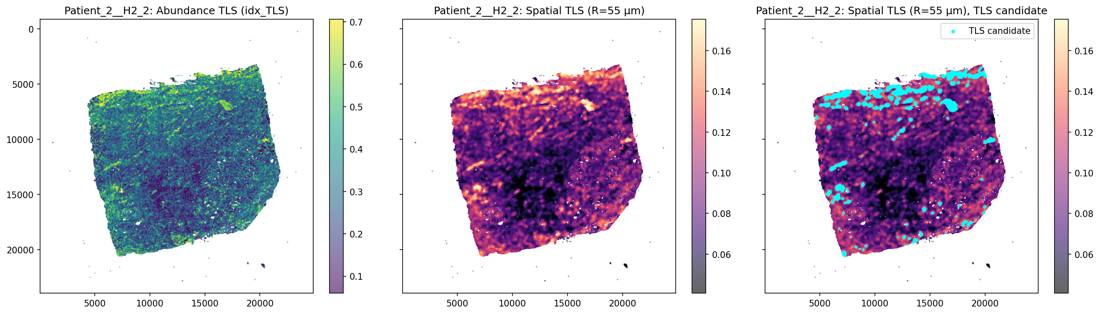

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_2_TLS_abundance_vs_spatial.png


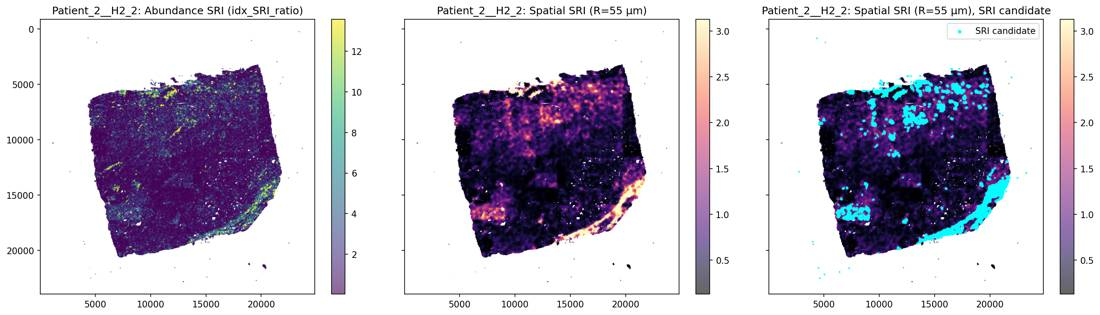

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_2_SRI_abundance_vs_spatial.png


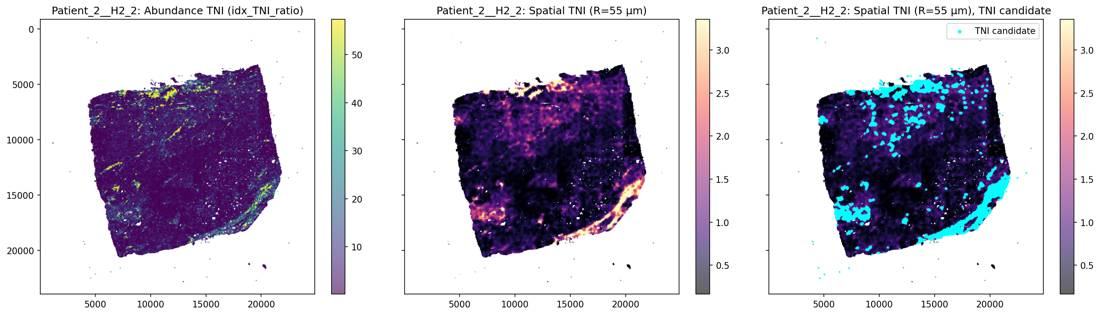

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_2_TNI_abundance_vs_spatial.png


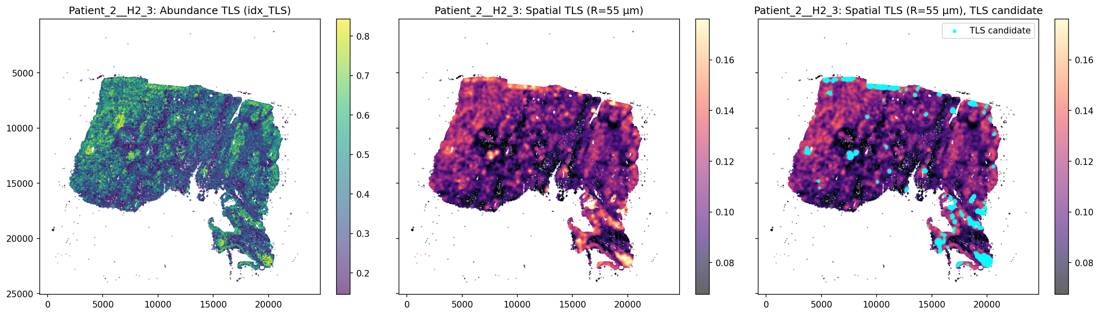

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_3_TLS_abundance_vs_spatial.png


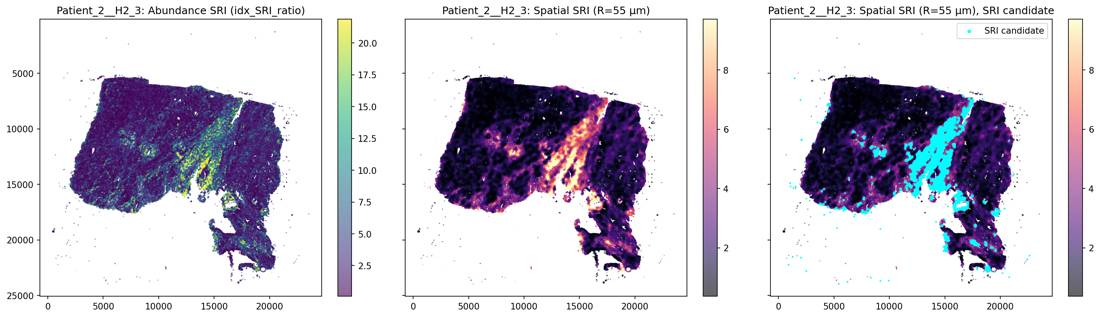

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_3_SRI_abundance_vs_spatial.png


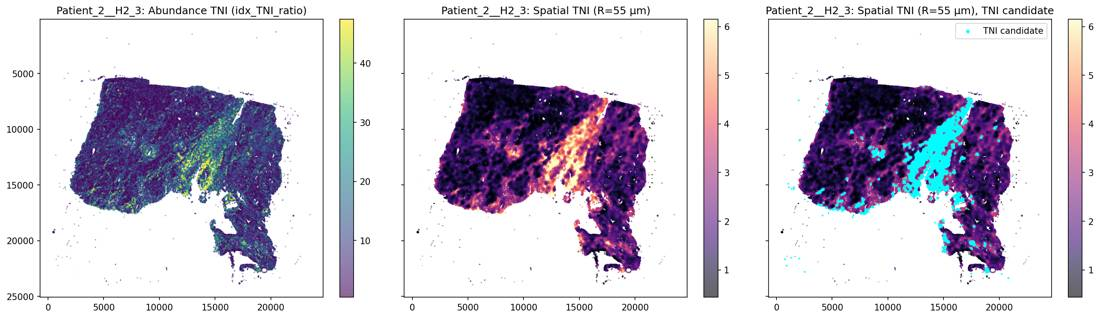

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_3_TNI_abundance_vs_spatial.png


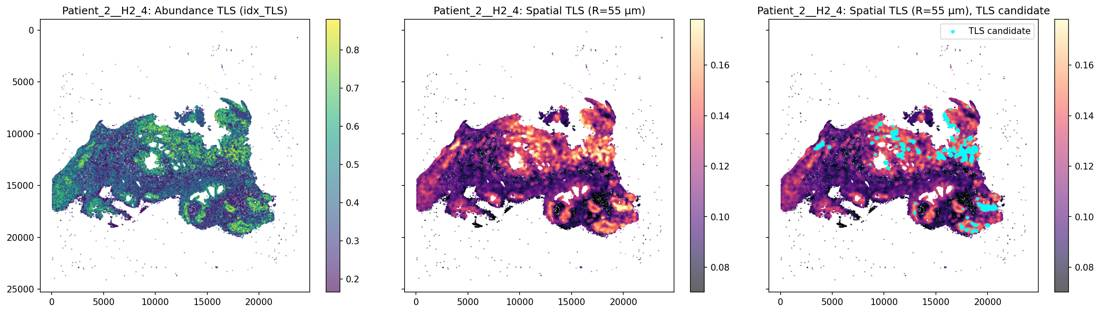

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_4_TLS_abundance_vs_spatial.png


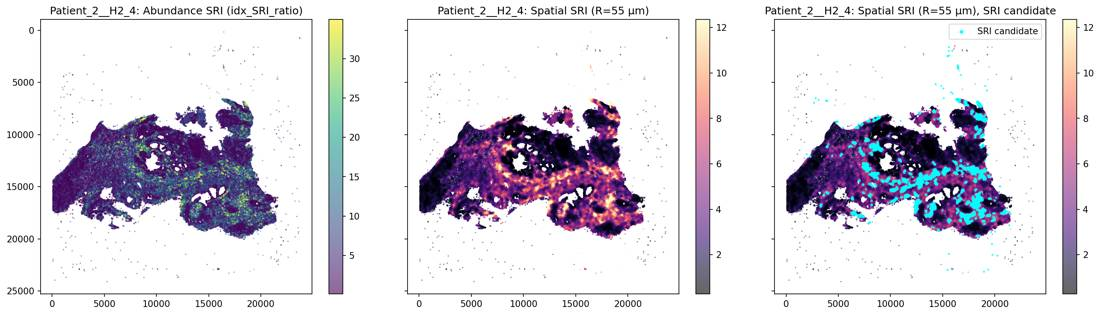

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_4_SRI_abundance_vs_spatial.png


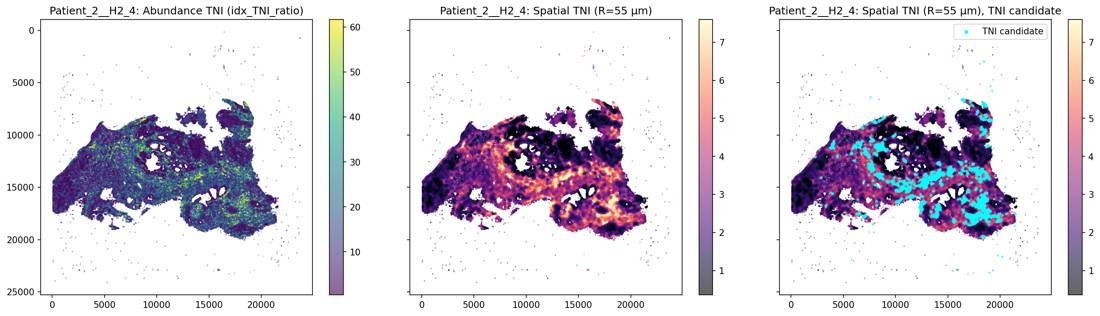

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_4_TNI_abundance_vs_spatial.png


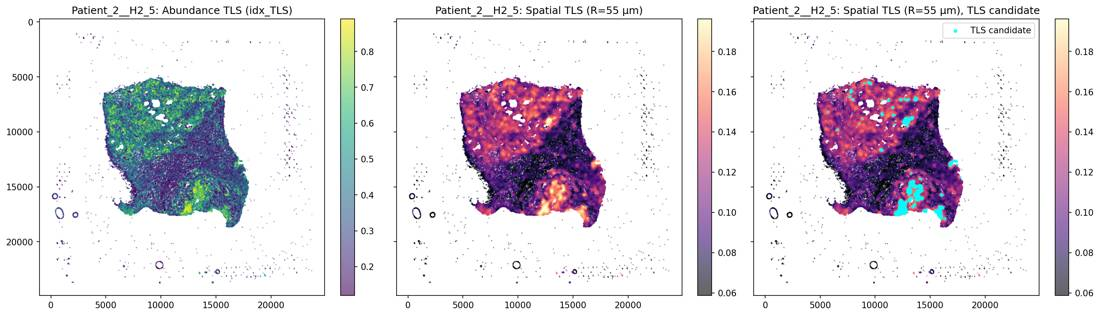

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_5_TLS_abundance_vs_spatial.png


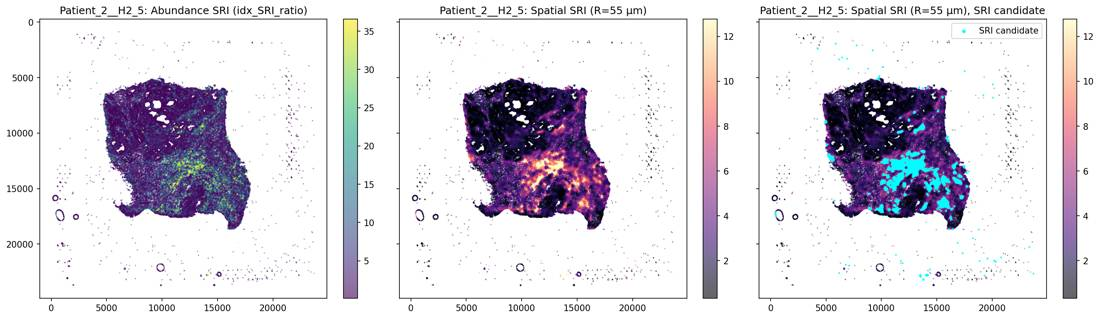

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_5_SRI_abundance_vs_spatial.png


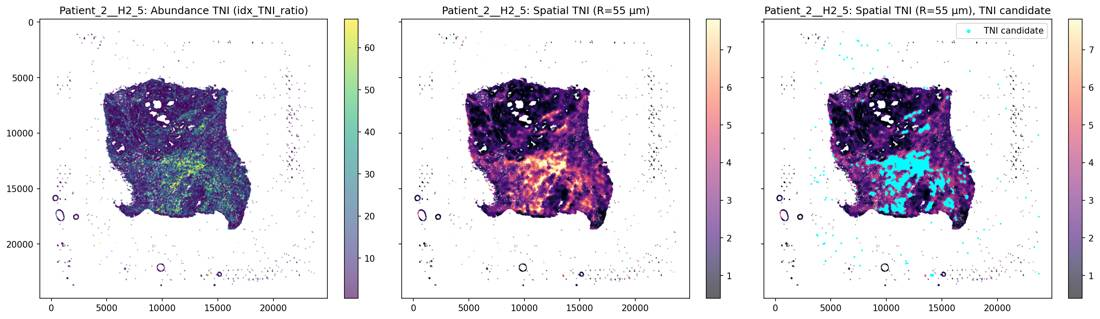

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_5_TNI_abundance_vs_spatial.png


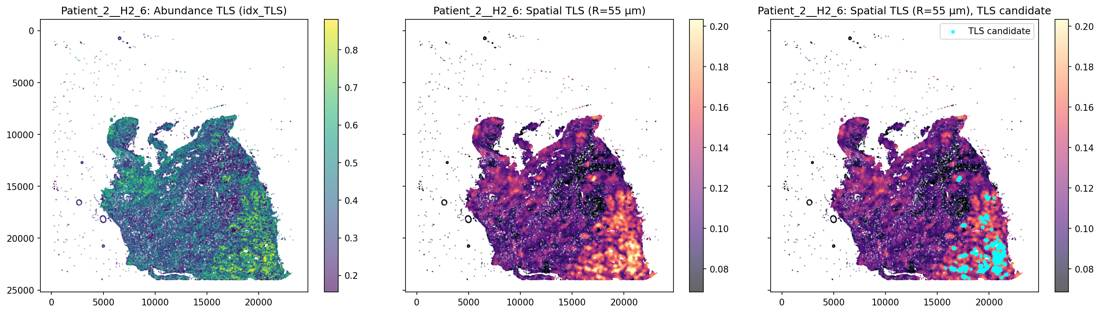

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_6_TLS_abundance_vs_spatial.png


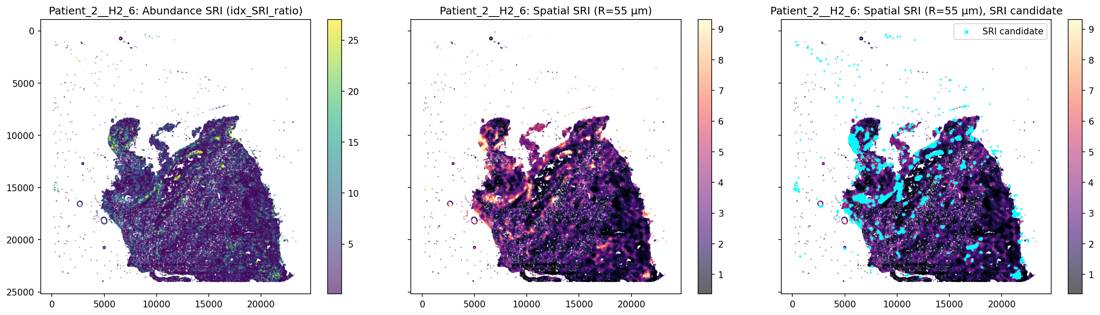

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_6_SRI_abundance_vs_spatial.png


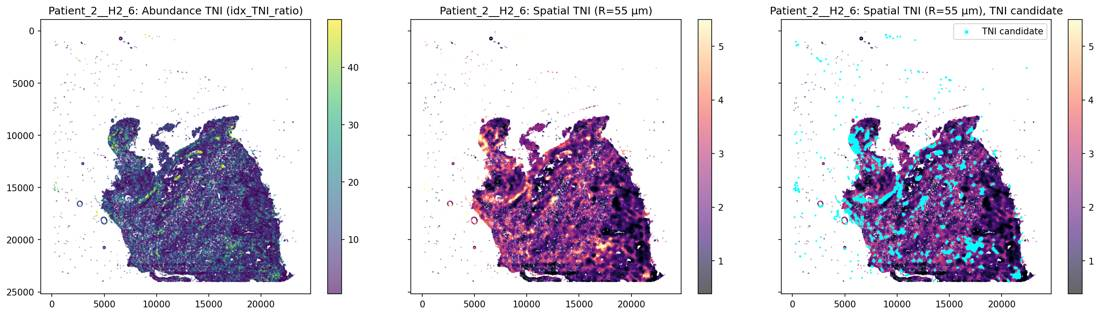

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H2_6_TNI_abundance_vs_spatial.png


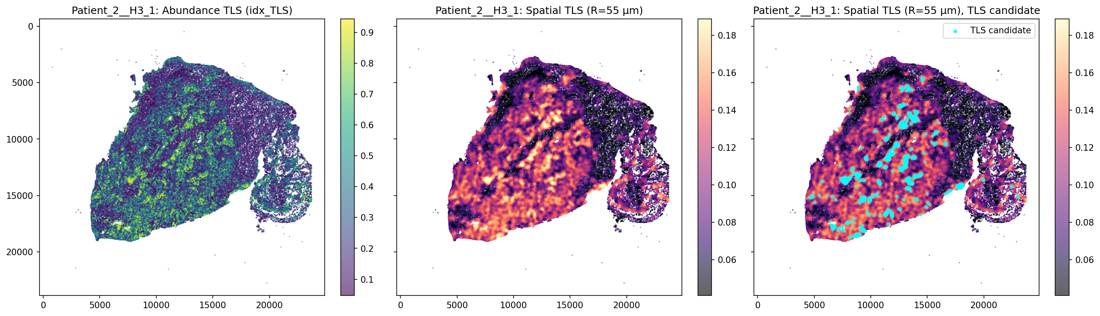

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_1_TLS_abundance_vs_spatial.png


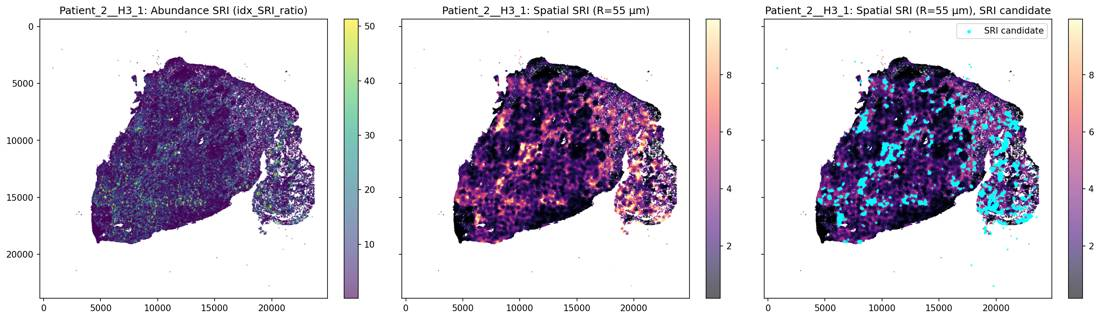

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_1_SRI_abundance_vs_spatial.png


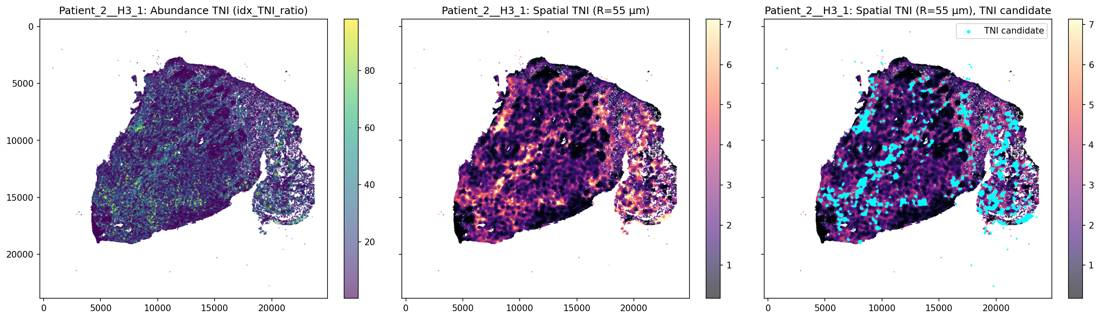

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_1_TNI_abundance_vs_spatial.png


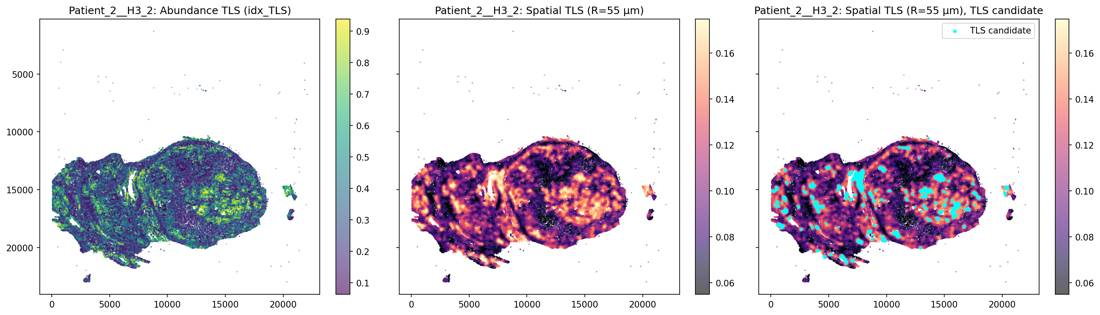

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_2_TLS_abundance_vs_spatial.png


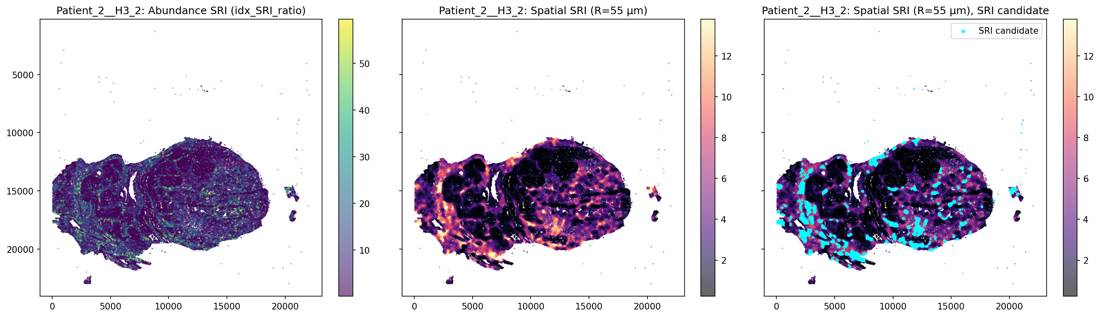

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_2_SRI_abundance_vs_spatial.png


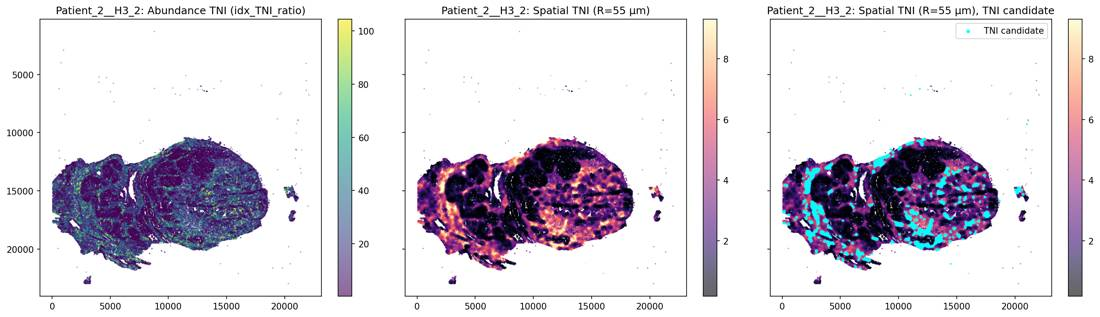

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_2_TNI_abundance_vs_spatial.png


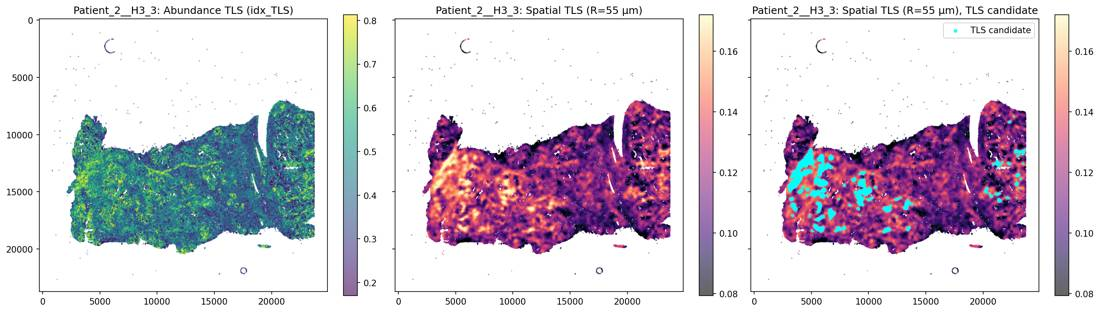

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_3_TLS_abundance_vs_spatial.png


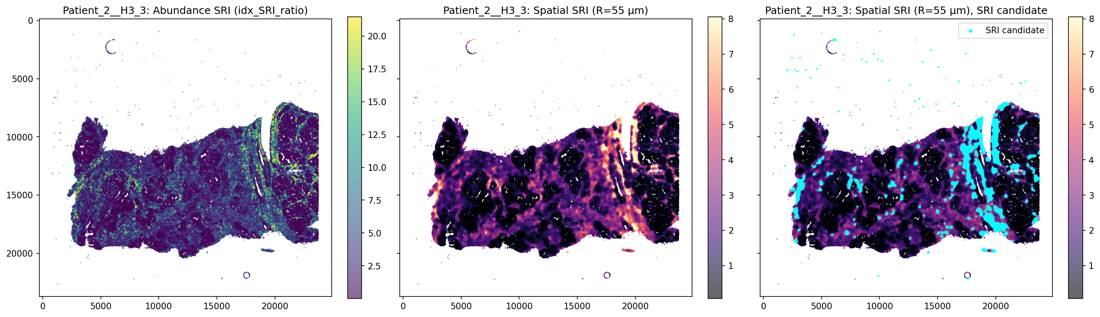

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_3_SRI_abundance_vs_spatial.png


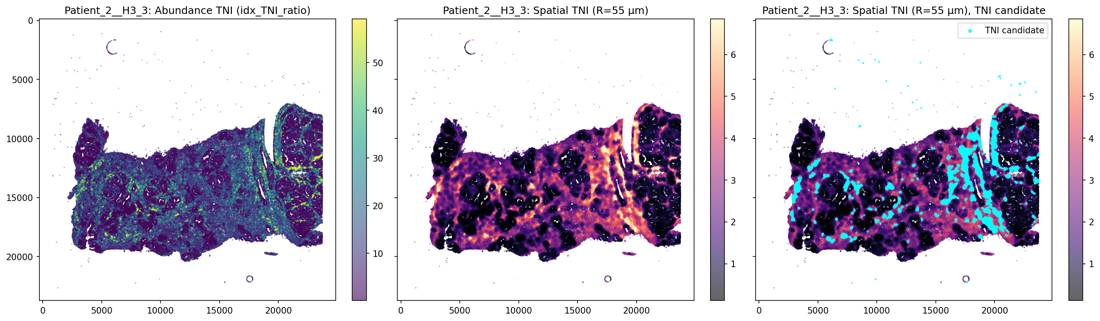

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_3_TNI_abundance_vs_spatial.png


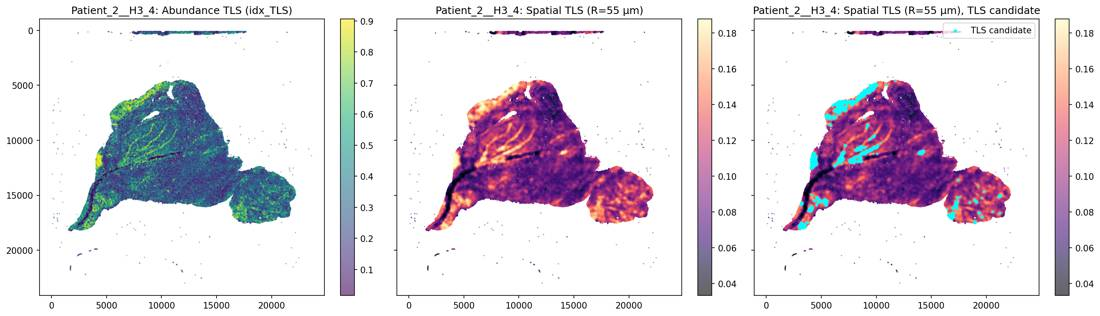

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_4_TLS_abundance_vs_spatial.png


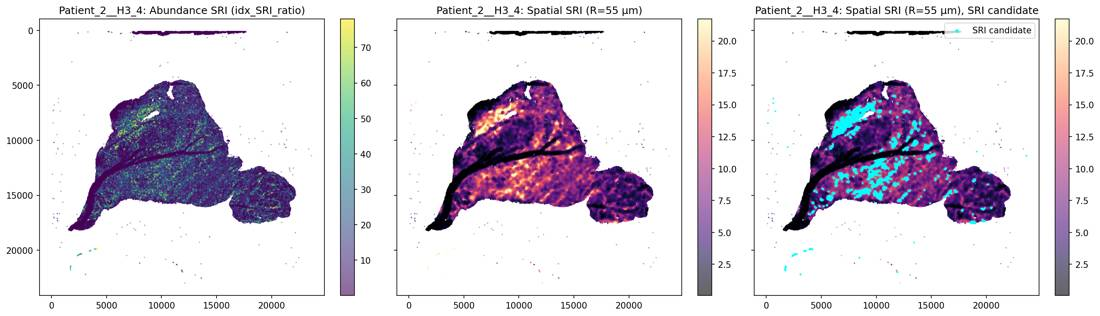

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_4_SRI_abundance_vs_spatial.png


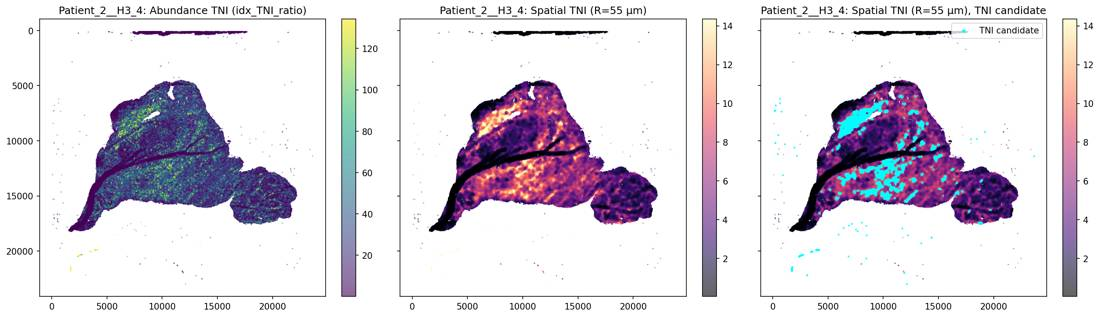

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_4_TNI_abundance_vs_spatial.png


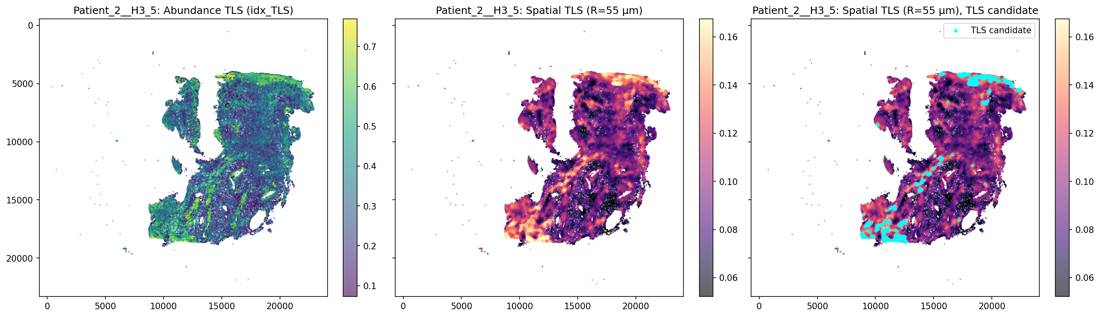

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_5_TLS_abundance_vs_spatial.png


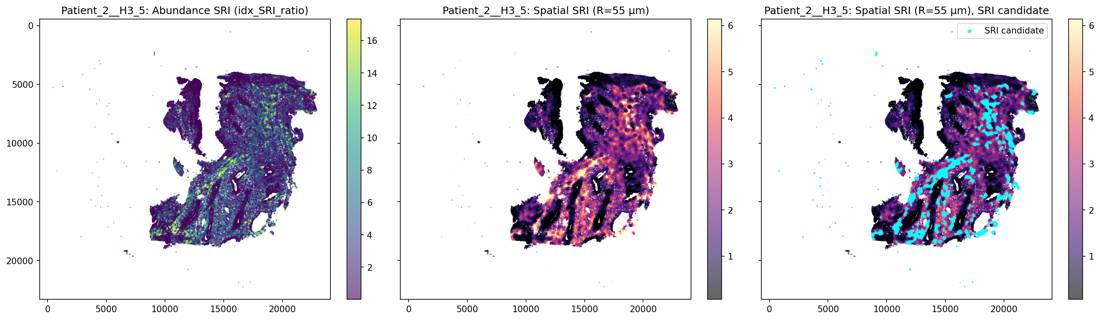

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_5_SRI_abundance_vs_spatial.png


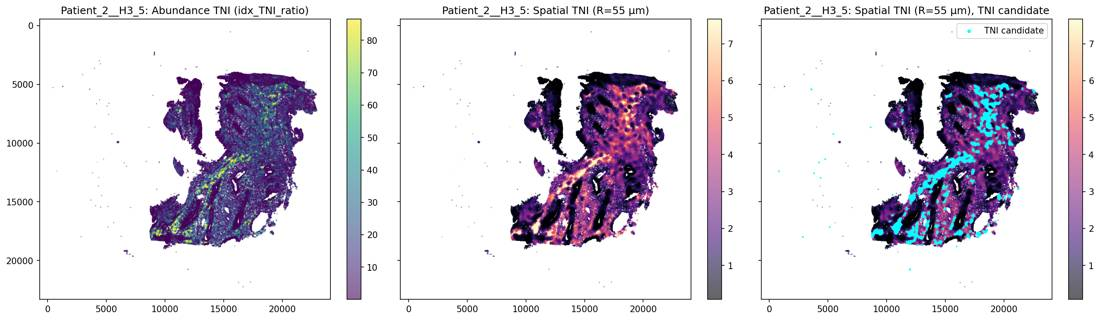

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_5_TNI_abundance_vs_spatial.png


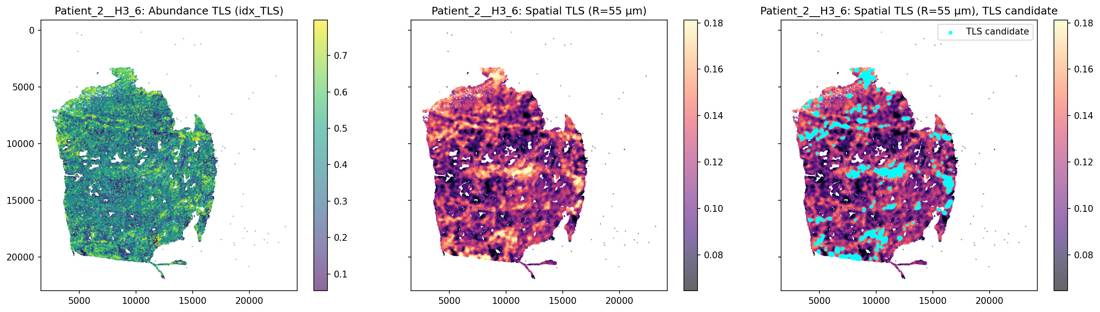

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_6_TLS_abundance_vs_spatial.png


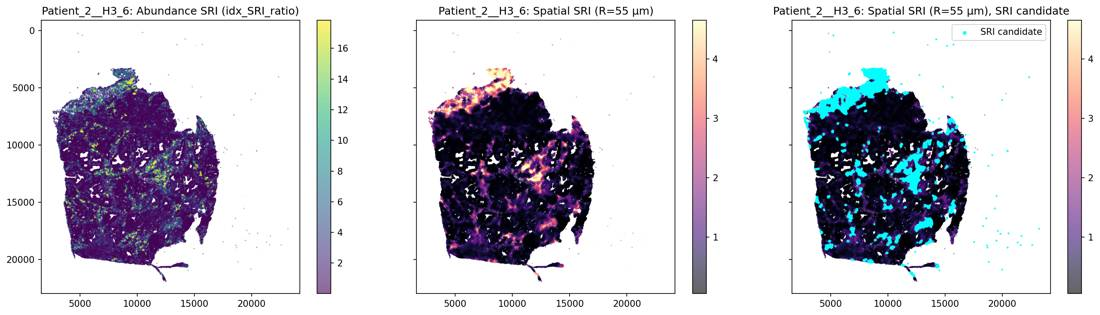

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_6_SRI_abundance_vs_spatial.png


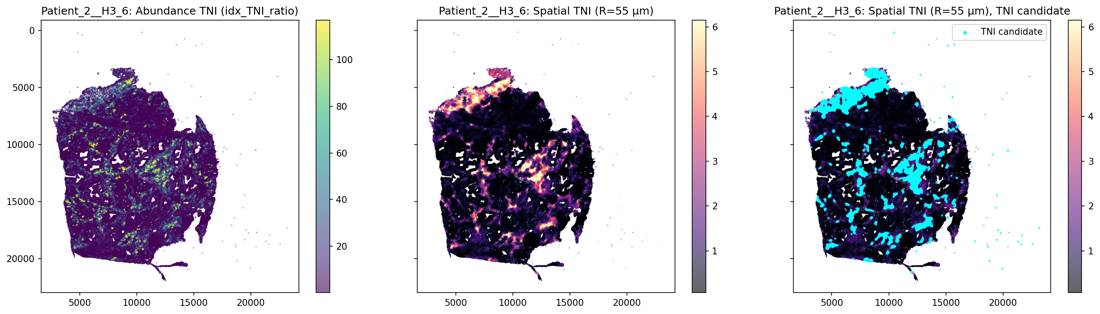

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__H3_6_TNI_abundance_vs_spatial.png


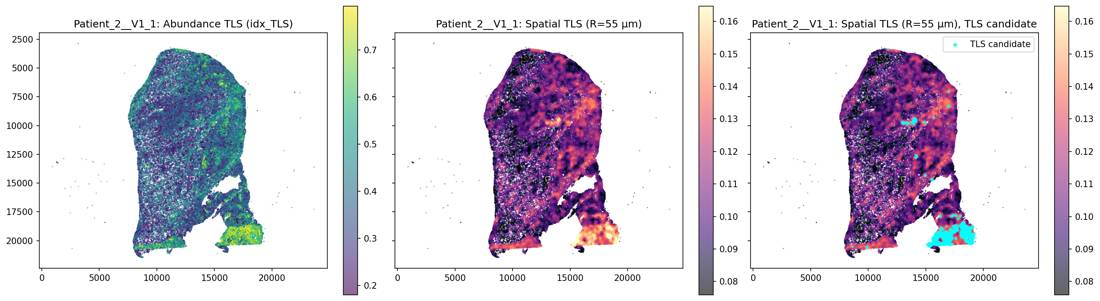

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_1_TLS_abundance_vs_spatial.png


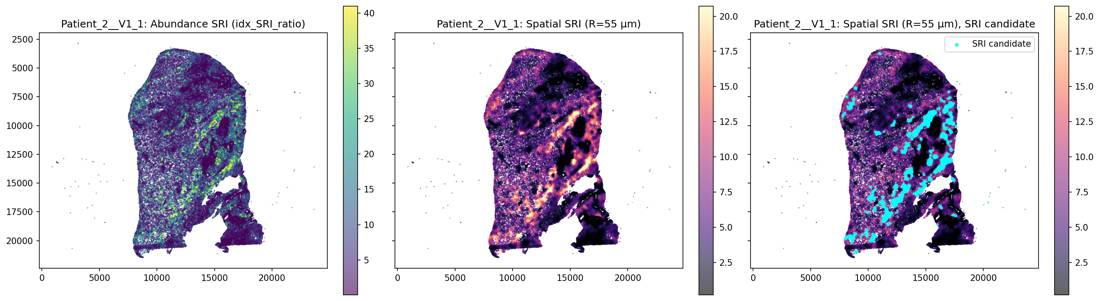

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_1_SRI_abundance_vs_spatial.png


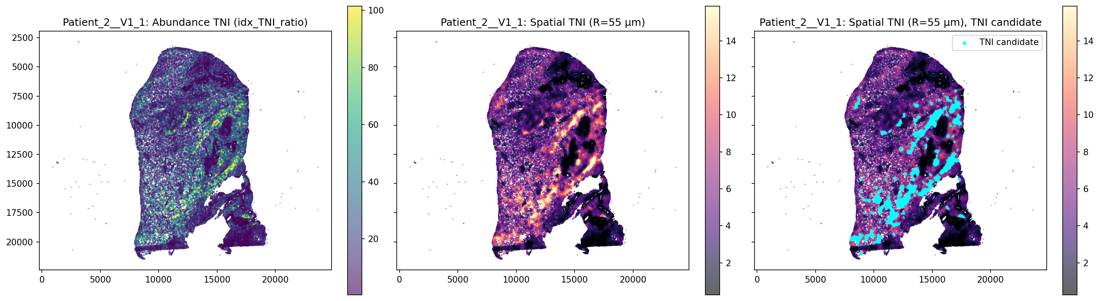

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_1_TNI_abundance_vs_spatial.png


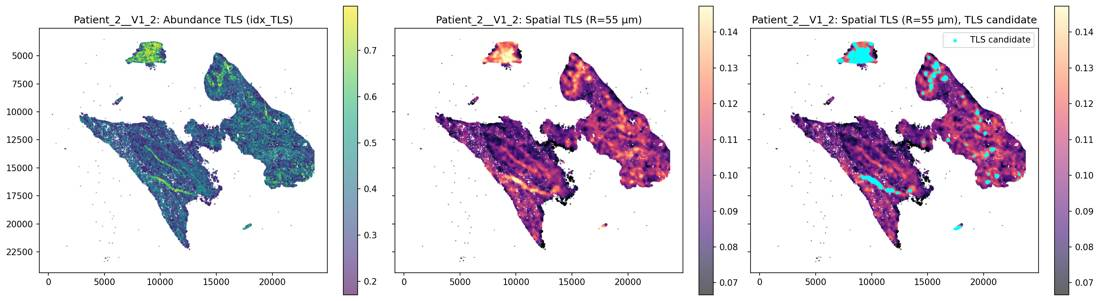

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_2_TLS_abundance_vs_spatial.png


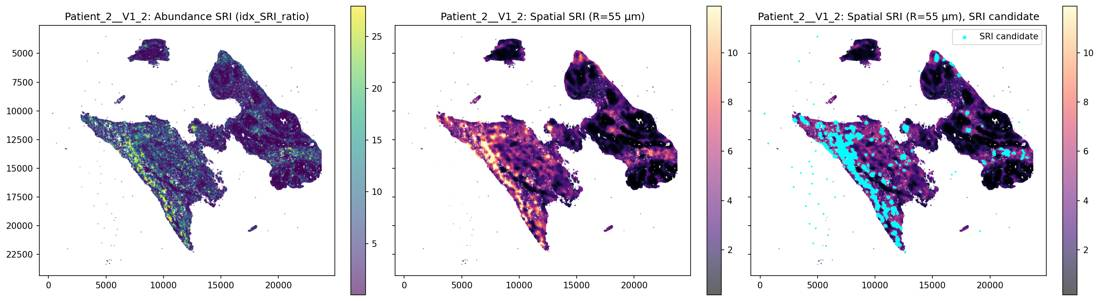

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_2_SRI_abundance_vs_spatial.png


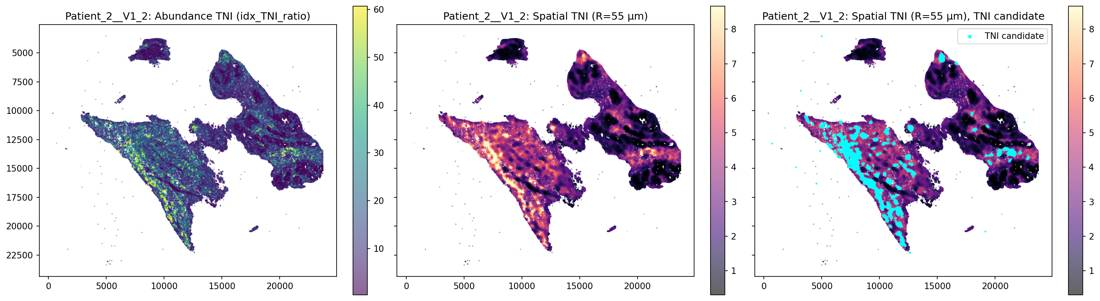

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_2_TNI_abundance_vs_spatial.png


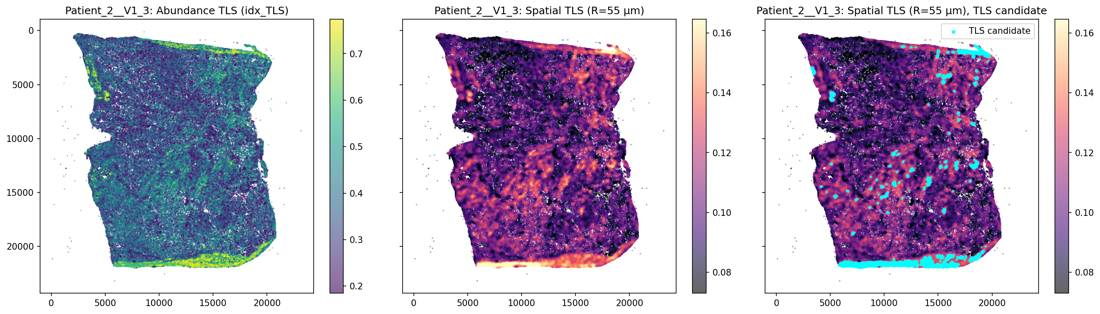

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_3_TLS_abundance_vs_spatial.png


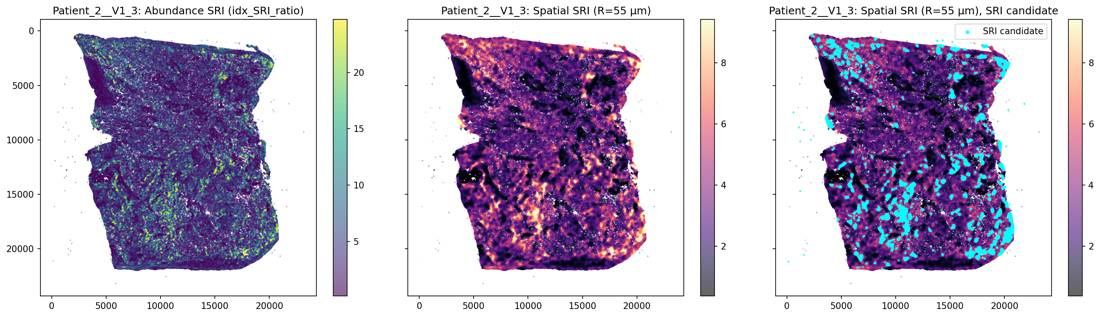

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_3_SRI_abundance_vs_spatial.png


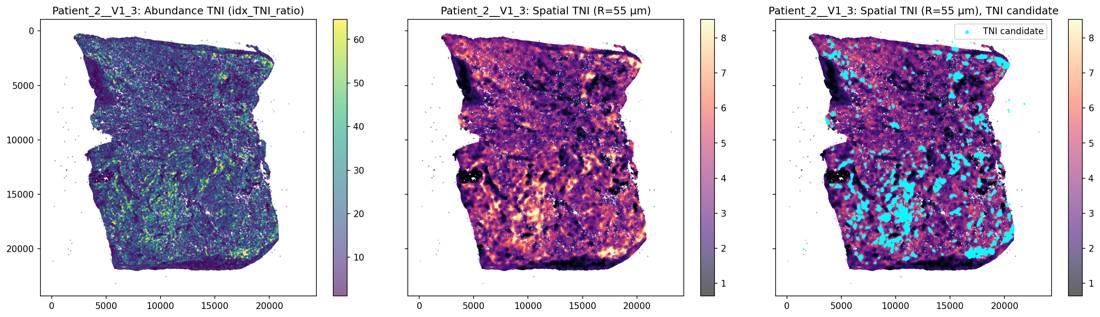

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_3_TNI_abundance_vs_spatial.png


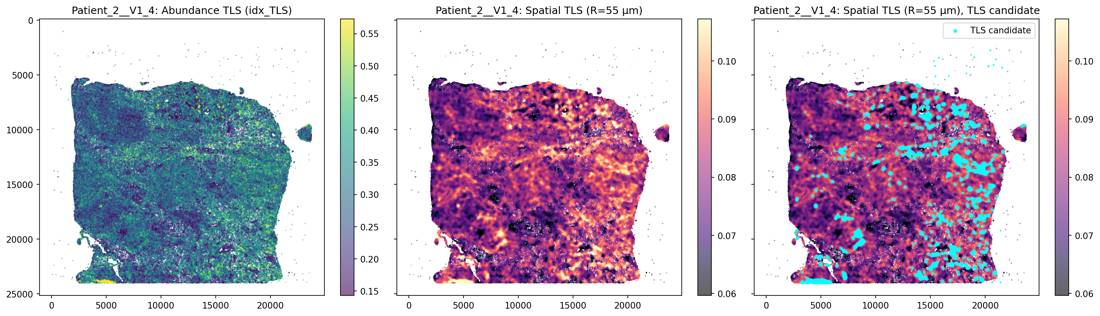

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_4_TLS_abundance_vs_spatial.png


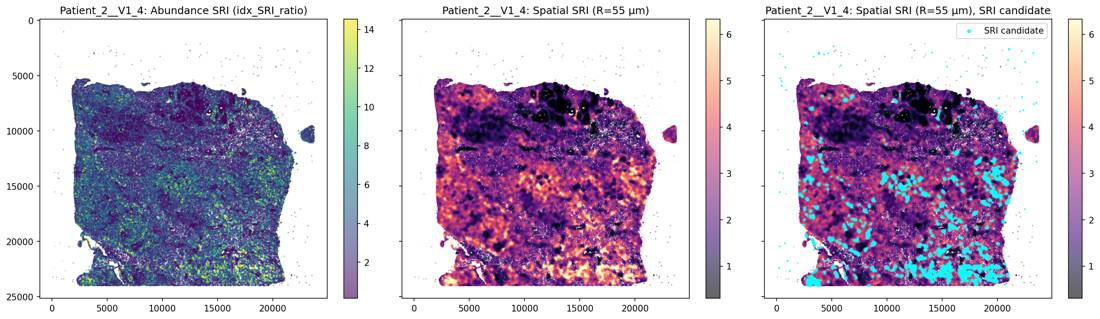

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_4_SRI_abundance_vs_spatial.png


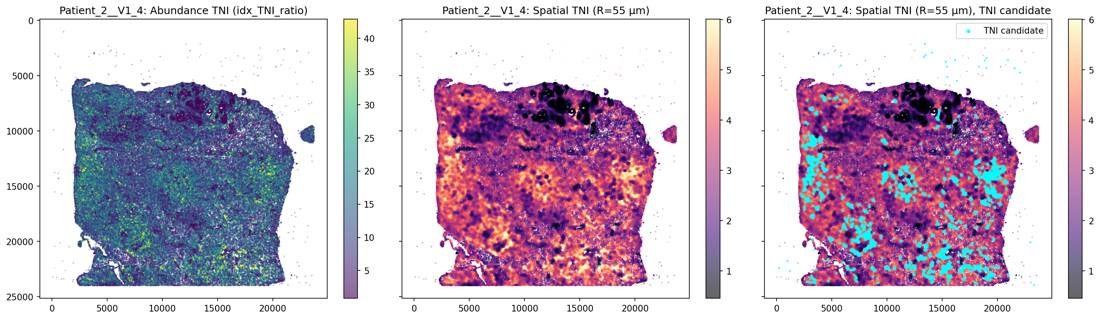

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_4_TNI_abundance_vs_spatial.png


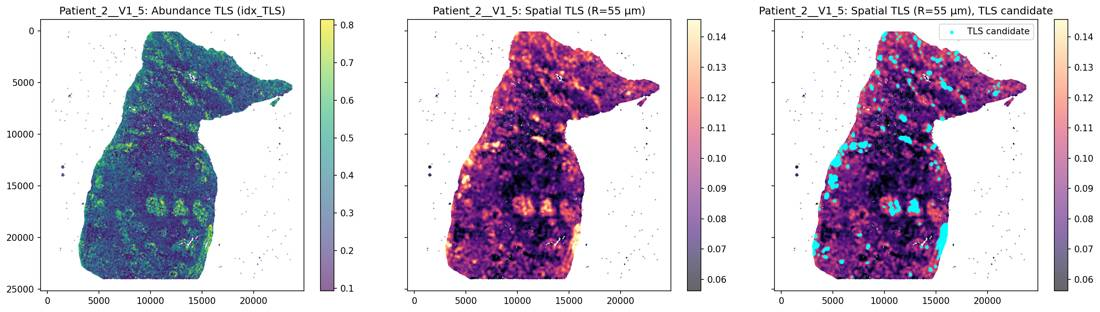

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_5_TLS_abundance_vs_spatial.png


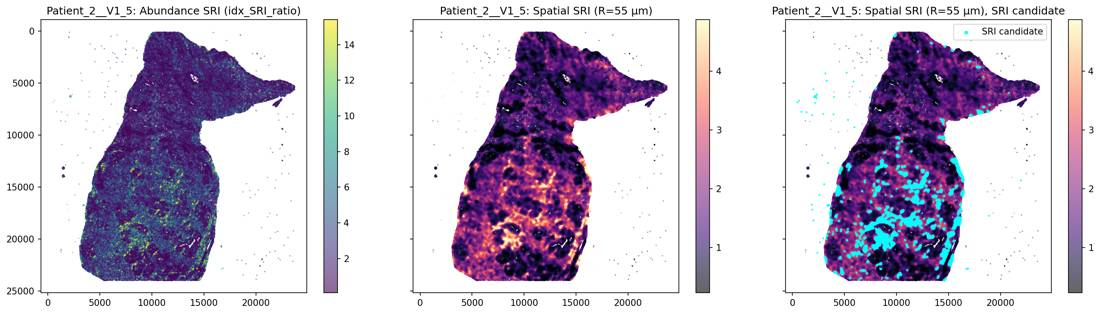

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_5_SRI_abundance_vs_spatial.png


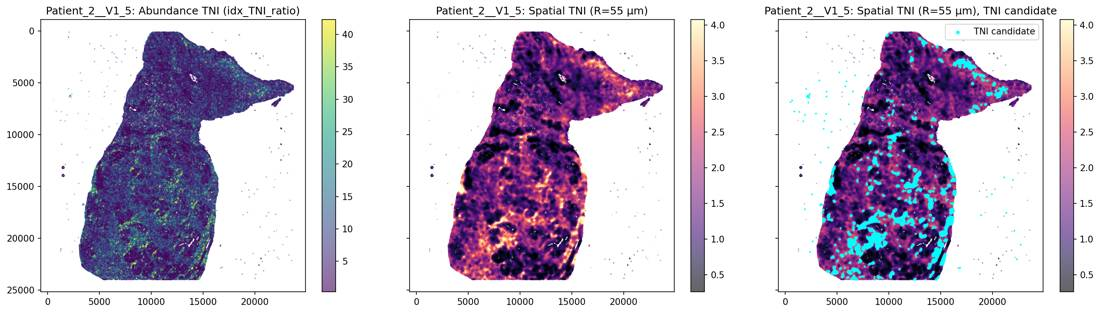

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_5_TNI_abundance_vs_spatial.png


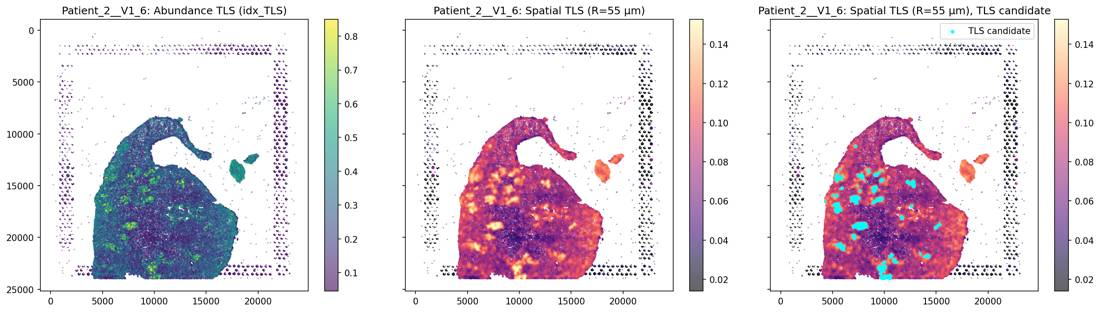

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_6_TLS_abundance_vs_spatial.png


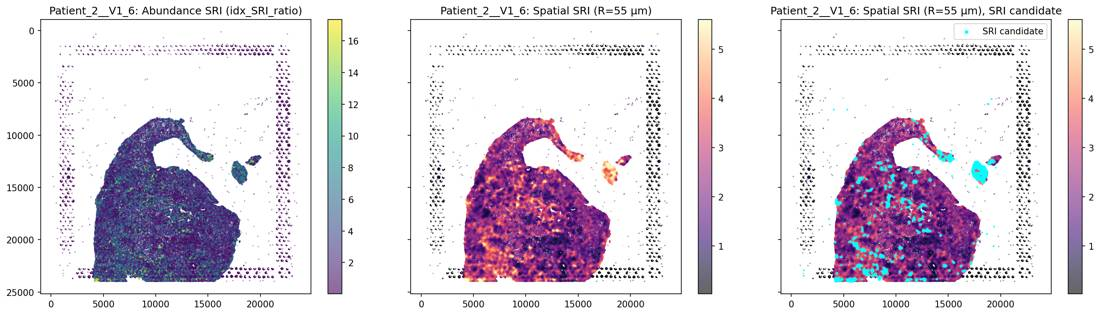

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_6_SRI_abundance_vs_spatial.png


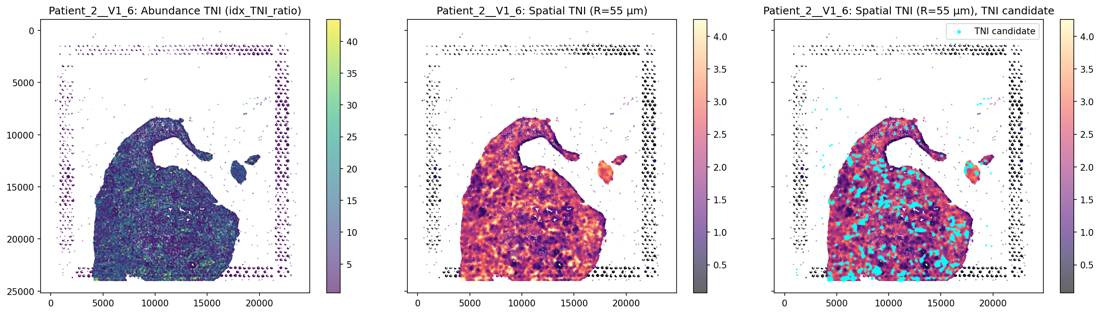

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V1_6_TNI_abundance_vs_spatial.png


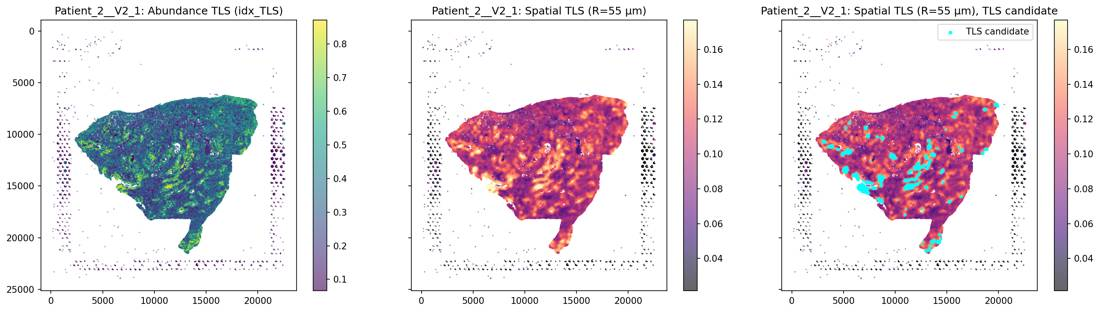

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_1_TLS_abundance_vs_spatial.png


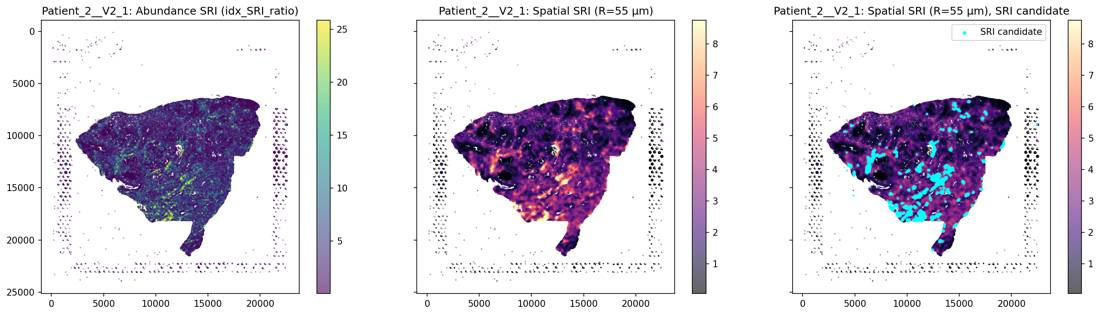

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_1_SRI_abundance_vs_spatial.png


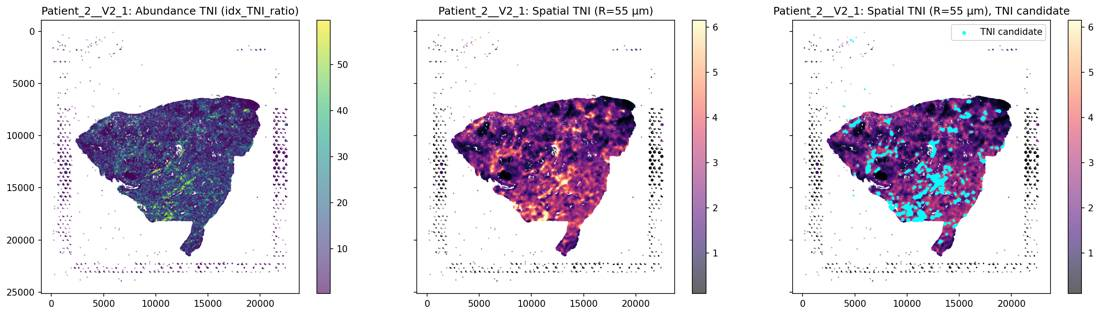

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_1_TNI_abundance_vs_spatial.png


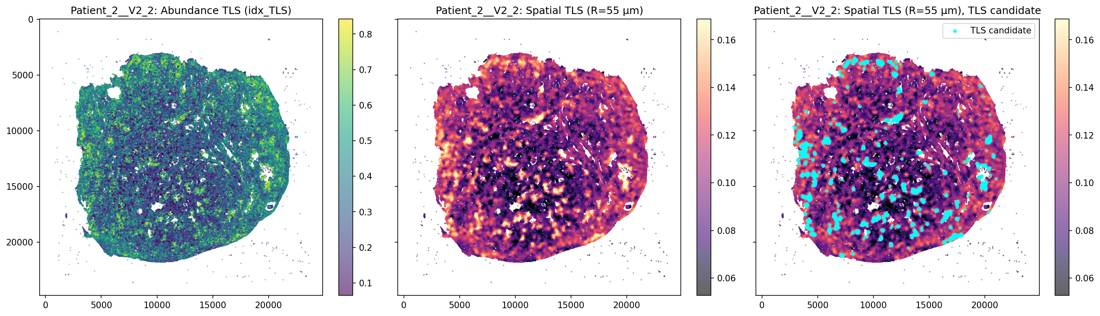

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_2_TLS_abundance_vs_spatial.png


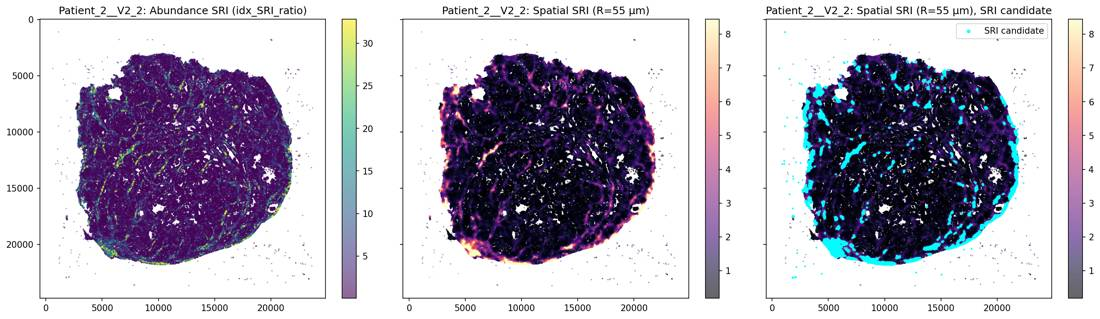

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_2_SRI_abundance_vs_spatial.png


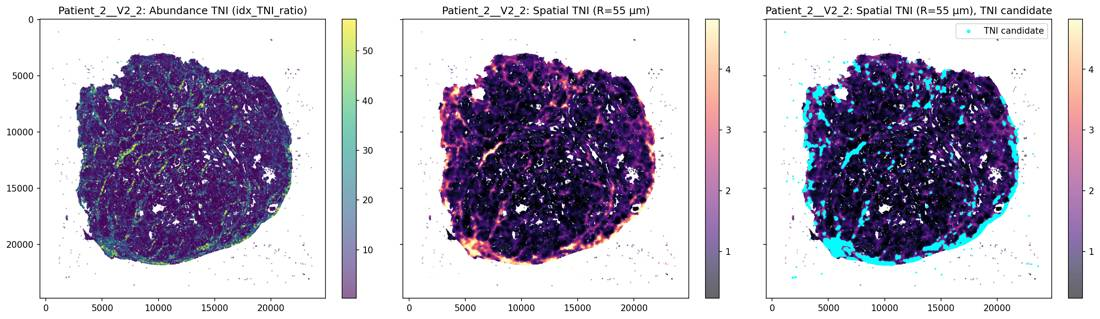

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_2_TNI_abundance_vs_spatial.png


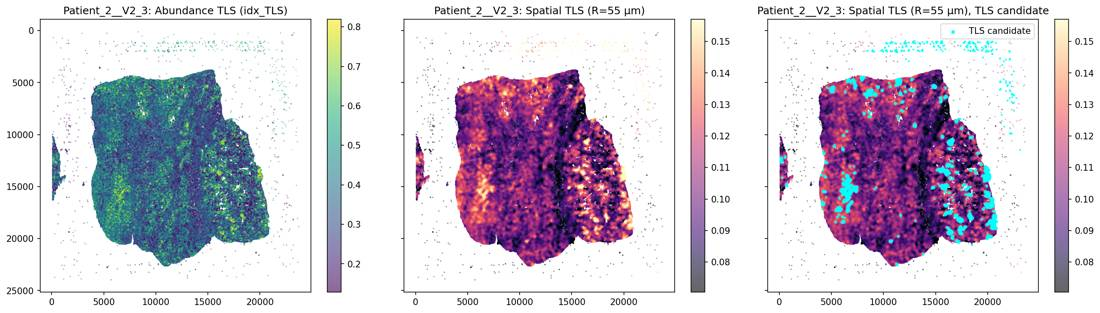

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_3_TLS_abundance_vs_spatial.png


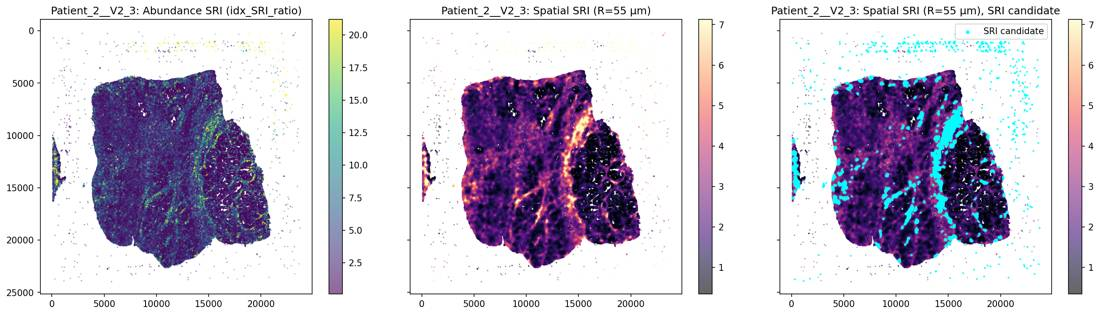

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_3_SRI_abundance_vs_spatial.png


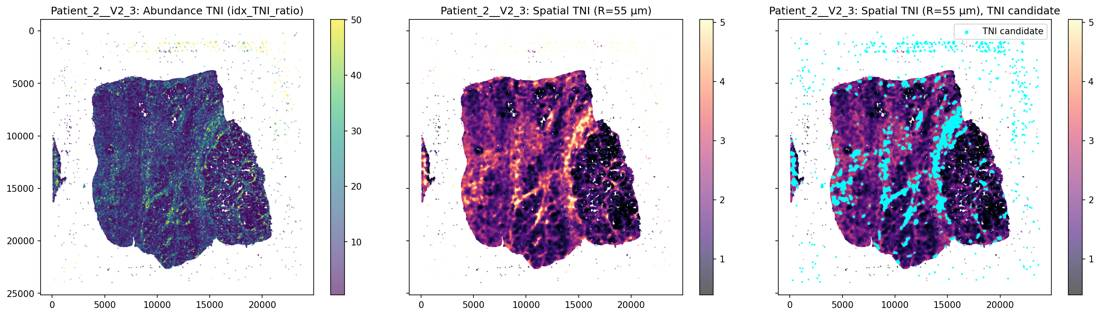

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_3_TNI_abundance_vs_spatial.png


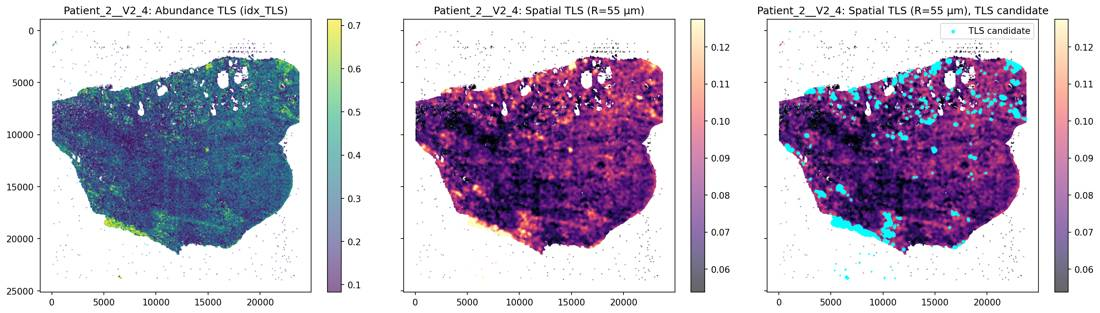

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_4_TLS_abundance_vs_spatial.png


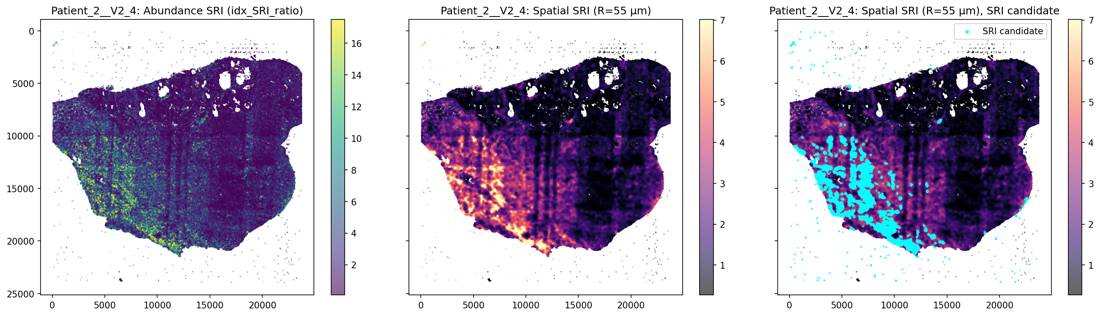

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_4_SRI_abundance_vs_spatial.png


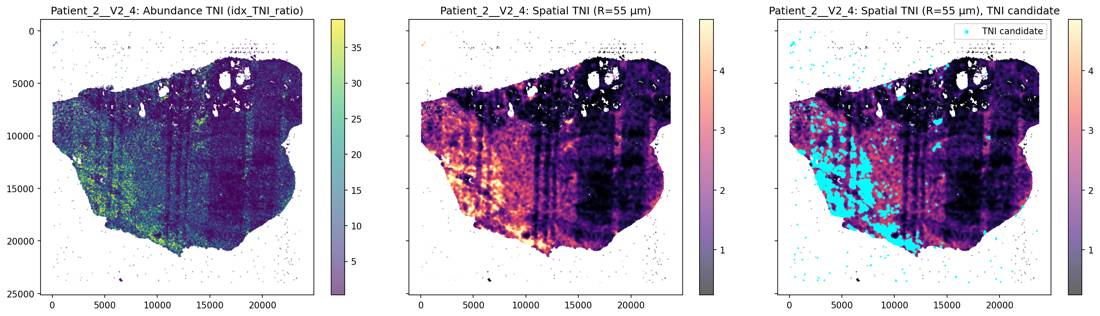

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_4_TNI_abundance_vs_spatial.png


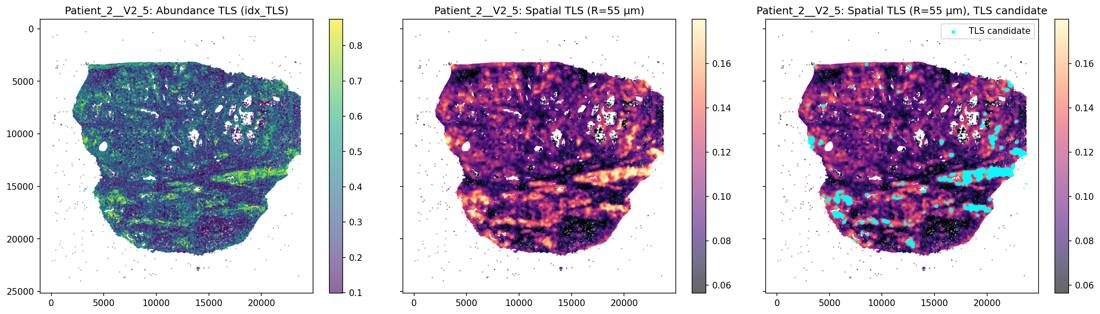

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_5_TLS_abundance_vs_spatial.png


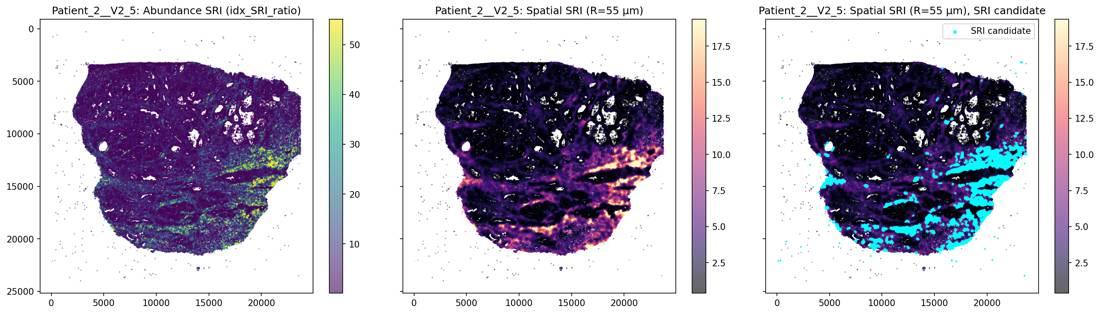

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_5_SRI_abundance_vs_spatial.png


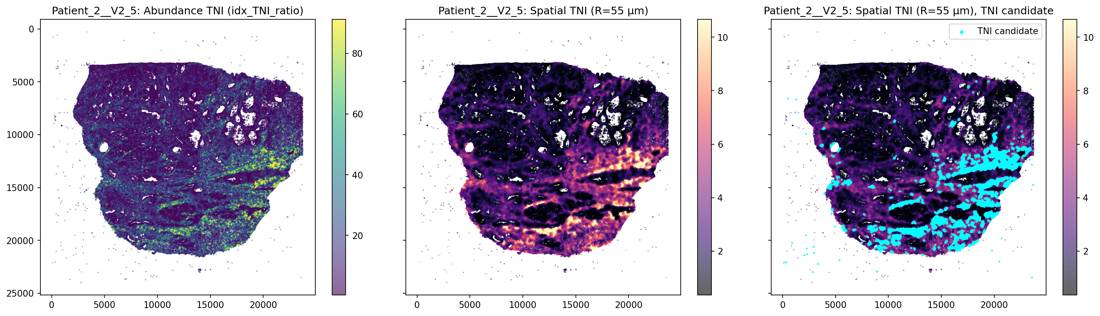

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_5_TNI_abundance_vs_spatial.png


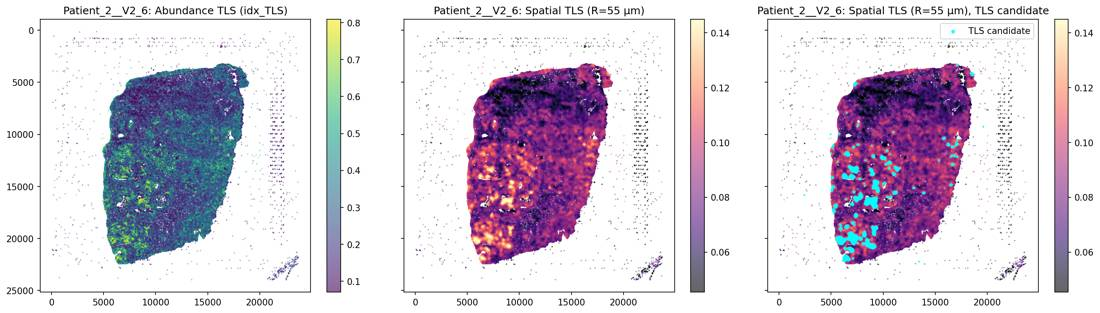

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_6_TLS_abundance_vs_spatial.png


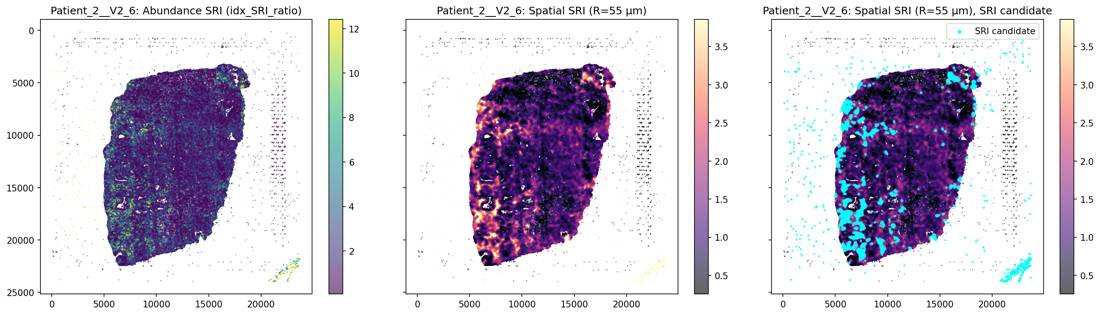

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_6_SRI_abundance_vs_spatial.png


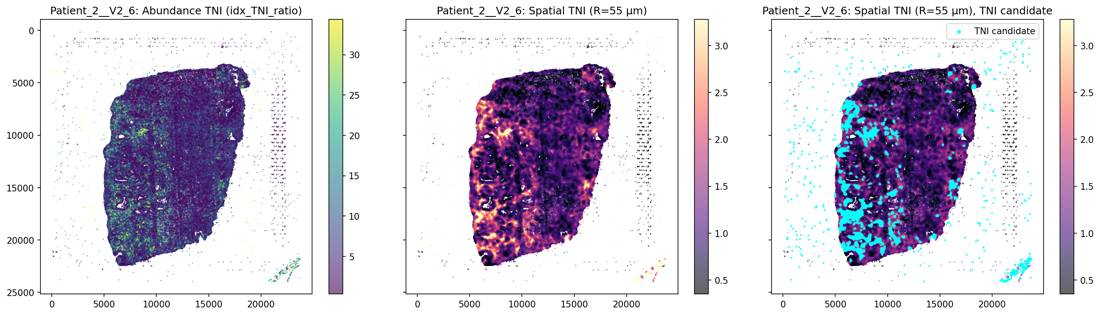

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_2__V2_6_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/Prostate/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, PROSTATE_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, PROSTATE_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, PROSTATE_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant.insert(1, "section", tls_quant["sample"].str.split("__").str[-1])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=fig_dir / f"{sample}_TLS_abundance_vs_spatial.png",
    )
    plt.close(fig)
    show_preview(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png",
        )
        plt.close(fig)
        show_preview(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
